# Latent TTA mit Größe als zusätzlichem Signal — Plots zu den Aussagen

**Frage aus dem letzten Treffen.** μ̂ steigt bei der TTA weiter, auch wenn der echte Dice nicht mehr
mitgeht, und κ steigt ebenfalls, deshalb hilft Gradient Descent auf die Unsicherheit nicht. Idee: κ
durch ein Signal ersetzen, das Über- und Untersegmentierung direkt misst, nämlich die Anzahl
**False Positives (FP)** und **False Negatives (FN)** mit Anker bei 0. Bevor wir dafür einen Head
trainieren, testen wir mit einem **Oracle**, ob dieses Signal überhaupt etwas bringt.

**Setup.** Wie beim letzten Treffen: PMRI, drei Domain Shifts (jeweils Test-Domäne):
**3T → 1.5T**, **PROMISE12**, **1.5T → 3T**. U-Net fest, Score-Predictor (Head liest die Features
vor der InstanceNorm, plus Logits) sagt μ̂ voraus. Pro Bild wird eine kanalweise Affine
γ·z + β an Swivel 0 und 17 angepasst, Adam, lr 0.01, **100 Schritte**. 5 Score-Predictoren;
Kennzahlen sind über alle Fälle und Predictoren gemittelt.

**Das neue Signal.** FP und FN als zwei Zahlen (ohne Pixelkarte) sagen der TTA nur, *wie viel*
Prostata es gibt, nicht *wo*: Aus der aktuellen Maske P folgt die echte Größe
|G| = |P| − FP + FN. Wir bestimmen deshalb **einmal vor der Adaption** aus den echten FP₀ und FN₀
der unadaptierten Maske die Zielgröße und bestrafen dann bei jedem Schritt die Abweichung der
weichen Maskengröße S = Σ p (Summe der Vordergrund-Wahrscheinlichkeiten) davon:

$$\max_{\gamma,\beta}\; \hat\mu \;-\; \lambda\,\big(\log(1+S) - \log(1+\hat G)\big)^2,
\qquad \hat G = |P_0| - \mathrm{FP}_0\,(1+\varepsilon_{FP}) + \mathrm{FN}_0\,(1+\varepsilon_{FN})$$

- **O3 (Größen-Oracle):** ε = 0, also Ĝ = |G| exakt. λ = 0.1 und λ = 1.
- **C (verrauschtes Oracle):** ε_FP, ε_FN ~ U(−n, n) unabhängig pro Bild, n = 10 / 20 / 30 %, λ = 1.
  Simuliert einen Head, der FP und FN nur ungefähr trifft.

κ wird nicht mehr benutzt. Der Größenterm ersetzt κ als zweites Signal.

| Abkürzung | Bedeutung |
|---|---|
| **μ̂-TTA** | Gradient Ascent nur auf μ̂ (Referenz aus dem letzten Treffen, gleiche Predictoren) |
| **μ̂ + Größe (λ)** | μ̂ plus Größenterm mit exaktem Ĝ (O3, braucht Labels) |
| **λ = 1, ε = n** | wie oben, aber FP₀ und FN₀ mit ±n verrauscht (C, braucht Labels) |
| **Threshold-Oracle (pro Bild / global)** | keine Adaption, beste Logit-Schwelle pro Bild bzw. für die ganze Domäne (braucht Labels) |
| **FP/FN getrennt / gemeinsam (λ)** | μ̂ plus echte FP und FN der aktuellen Maske in jedem Schritt (Abschnitt 8, braucht Labels) |
| **Soft-Dice-Oracle** | dieselbe TTA, aber Ascent auf den *echten* weichen Dice (braucht Labels) |

Alle Oracles sind **Referenzen, keine Methoden**.

**Kurzfassung**
- Die Größe als zweites Signal hilft auf allen drei Shifts und für alle 5 Predictoren:
  +0.03 / +0.04 / +0.05 Dice gegenüber der μ̂-TTA (λ = 1). Auf 1.5T → 3T, wo die μ̂-TTA fast nichts
  bringt, ist es der größte Gewinn.
- Danach gilt FP ≈ FN: Die Masken haben die richtige Größe, aber der Rest des Fehlers liegt an der
  *Lage* der Grenze. Den schließt die Größe nicht; vom Abstand zum Soft-Dice-Oracle schließen wir nur
  15–18 %.
- Rauschen von ±30 % auf FP₀ und FN₀ kostet höchstens 0.003 Dice. Das entspricht aber nur einem
  typischen Fehler von 4–7 % auf der Zielgröße, weil sich die beiden Fehler teilweise aufheben und
  FP₀, FN₀ klein gegenüber |G| sind.

- **FP/FN in jedem Schritt (Abschnitt 8):** Mit den echten FP und FN der *aktuellen* Maske in jedem
  Schritt kommt man viel näher ans Soft-Dice-Oracle (λ = 1: 0.889 / 0.875 / 0.677), aber nur mit der
  Strafe log(1 + FP + FN). Mit log(1 + FP) + log(1 + FN) wird es schlechter als die μ̂-TTA, weil die
  Adaption FP auf 0 drückt und FN wachsen lässt.

**Gliederung**
1. Überblick
2. Unter- und Übersegmentierung (FP, FN, Größe)
3. Wo hilft die Größe?
4. Pro Fall: Größe vs. μ̂-TTA
5. Verlauf über die Schritte
6. Rauschen auf FP und FN (Run C)
7. Beispiele
8. FP/FN in jedem Schritt (FP/FN-Oracle)
9. Fazit und nächste Schritte

Alle Abbildungen werden zusätzlich als PNG nach `results/plots_treffen_03_11/` geschrieben.

In [ ]:
import glob, os, pickle, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

ROOT = os.path.abspath("../../../..")  # repo root
sys.path.insert(0, f"{ROOT}/src")
from apps.plot_latent_tta import _overlay, _crop_box

FIG_DIR = f"{ROOT}/results/plots_treffen_03_11"
os.makedirs(FIG_DIR, exist_ok=True)

DOMAINS = {"threet-to-onepointfivet": "3T → 1.5T", "promise12": "PROMISE12",
           "onepointfivet-to-threet": "1.5T → 3T"}
PREDICTORS = range(5)
VARIANTS = {   # name -> results folder
    "mu": "latent_tta_prenorm",
    "size0.1": "latent_tta_mu_size_w0.1",
    "size1": "latent_tta_mu_size_w1.0",
    "noise0.1": "latent_tta_mu_size_w1.0_noise0.1",
    "noise0.2": "latent_tta_mu_size_w1.0_noise0.2",
    "noise0.3": "latent_tta_mu_size_w1.0_noise0.3",
    "oracle": "latent_tta_oracle",
    "sep0.1": "latent_tta_mu_fpfn_w0.1",
    "sep1": "latent_tta_mu_fpfn_w1.0",
    "joint0.1": "latent_tta_mu_fpfn_joint_w0.1",
    "joint1": "latent_tta_mu_fpfn_joint_w1.0",
}
MAIN = ["mu", "size0.1", "size1", "oracle"]
SIZE = ["size0.1", "size1"]
NOISE = {0.0: "size1", 0.1: "noise0.1", 0.2: "noise0.2", 0.3: "noise0.3"}
LABEL = {"mu": "μ̂-TTA", "size0.1": "μ̂ + Größe (λ = 0.1)", "size1": "μ̂ + Größe (λ = 1)",
         "noise0.1": "λ = 1, ε = 10 %", "noise0.2": "λ = 1, ε = 20 %", "noise0.3": "λ = 1, ε = 30 %",
         "oracle": "Soft-Dice-Oracle",
         "sep0.1": "FP/FN Oracle getrennt (λ = 0.1)", "sep1": "FP/FN Oracle getrennt (λ = 1)",
         "joint0.1": "FP/FN Oracle gemeinsam (λ = 0.1)", "joint1": "FP/FN Oracle gemeinsam (λ = 1)"}
FPFN = ["sep0.1", "sep1", "joint0.1", "joint1"]

# colours: fixed hue per configuration (categorical slots blue / orange / violet / aqua,
# validated for CVD separation), references in grey; μ̂-TTA and the oracle keep their
# colours from the 27.10. notebook
# FP/FN oracle (section 8): ochre = separate, navy = joint form; λ = 0.1 hollow / hatched, λ = 1 filled
COL = {"mu": "#2a78d6", "size0.1": "#eb6834", "size1": "#6250d6", "oracle": "#1baf7a",
       "sep0.1": "#c98500", "sep1": "#c98500", "joint0.1": "#0d366b", "joint1": "#0d366b",
       "Threshold-Oracle": "#52514e", "Threshold global": "#52514e", "Ausgang": "#898781"}
GROUP_COL = {"verbessert": "#2a78d6", "unverändert": "#b5b3ad", "geschädigt": "#e34948"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
THR_LS = (0, (1, 1.5))
TOL = 0.05

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.precision", 3)
PCT = plt.matplotlib.ticker.PercentFormatter(1, decimals=0)


def show(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
KEYS = ("dice_before", "dice_after", "mu_before", "mu_after", "best_dice", "thr_oracle_dice",
        "thr_global_dice", "logit_drift", "dice_per_step", "mu_per_step",
        # only in runs after the size-oracle change
        "fp_before", "fn_before", "fp_after", "fn_after", "size_gt", "size_before", "size_after",
        "size_target", "hard_size_per_step", "size_loss_per_step",
        # only in runs after the FP/FN-oracle change
        "fp_soft_per_step", "fn_soft_per_step")


def load(folder, d, p, split="test"):
    path = glob.glob(f"{ROOT}/results/{folder}/pmri_{d}_*cleanHalf_{p}_*/latent_tta.pkl")
    if not path:
        return None
    assert len(path) == 1, (folder, d, p)
    with open(path[0], "rb") as f:
        ev = pickle.load(f)["evaluation"][f"{d}_{split}"]
    num = lambda t: t.float().numpy()
    r = {k: num(ev[k]) for k in KEYS if k in ev and getattr(ev[k], "numel", lambda: 0)() > 0}
    if "size_eps" in ev:
        r["size_eps"] = num(ev["size_eps"])[:, 0]          # [N, 2] (fp, fn), binary: one class
    r["examples"] = {k: v.float().numpy() for k, v in ev["examples"].items()}
    return r


R = {(v, d, p): load(f, d, p) for v, f in VARIANTS.items() for d in DOMAINS for p in PREDICTORS}
R = {k: r for k, r in R.items() if r is not None}
AVAIL = [v for v in VARIANTS if all((v, d, p) in R for d in DOMAINS for p in PREDICTORS)]
missing = [v for v in VARIANTS if v not in AVAIL]
assert all(v in AVAIL for v in MAIN + FPFN), missing
NOISE = {e: v for e, v in NOISE.items() if v in AVAIL}
for d in DOMAINS:   # every configuration sees the same cases in the same order
    ref = R["mu", d, 0]["dice_before"]
    assert all(np.allclose(R[v, d, p]["dice_before"], ref, atol=1e-4) for v in AVAIL for p in PREDICTORS)


def pooled(v, d, key):
    return np.concatenate([R[v, d, p][key] for p in PREDICTORS])


def per_pred(v, d, fn):
    return np.array([fn(R[v, d, p]) for p in PREDICTORS])


print({DOMAINS[d]: len(R["mu", d, 0]["dice_before"]) for d in DOMAINS}, "Testfälle je Predictor")
print("Konfigurationen:", [LABEL[v] for v in AVAIL], "| fehlt:", [LABEL[v] for v in missing] or "nichts")

{'3T → 1.5T': 481, 'PROMISE12': 1248, '1.5T → 3T': 1121} Testfälle je Predictor
Konfigurationen: ['μ̂-TTA', 'μ̂ + Größe (λ = 0.1)', 'μ̂ + Größe (λ = 1)', 'λ = 1, ε = 10 %', 'λ = 1, ε = 20 %', 'λ = 1, ε = 30 %', 'Soft-Dice-Oracle', 'FP/FN getrennt (λ = 0.1)', 'FP/FN getrennt (λ = 1)', 'FP/FN gemeinsam (λ = 0.1)', 'FP/FN gemeinsam (λ = 1)'] | fehlt: nichts


## 1 · Überblick

**Aussage:** Mit dem Größenterm liegt der mittlere Dice auf allen drei Shifts über der μ̂-TTA und
auf 3T → 1.5T und PROMISE12 auch über dem Threshold-Oracle pro Bild. Auf 1.5T → 3T bleibt er
darunter (0.590 vs. 0.625). Zum Soft-Dice-Oracle bleibt ein großer Abstand.

*Lesen:* Jeder Punkt ist der mittlere Dice einer Konfiguration; die kleinen Striche sind die 5
Predictoren einzeln. Grau gestrichelt: ohne Adaption; grau gepunktet: Threshold-Oracle pro Bild.
Hohler Kreis: Threshold-Oracle mit *einer* Schwelle für die ganze Domäne.

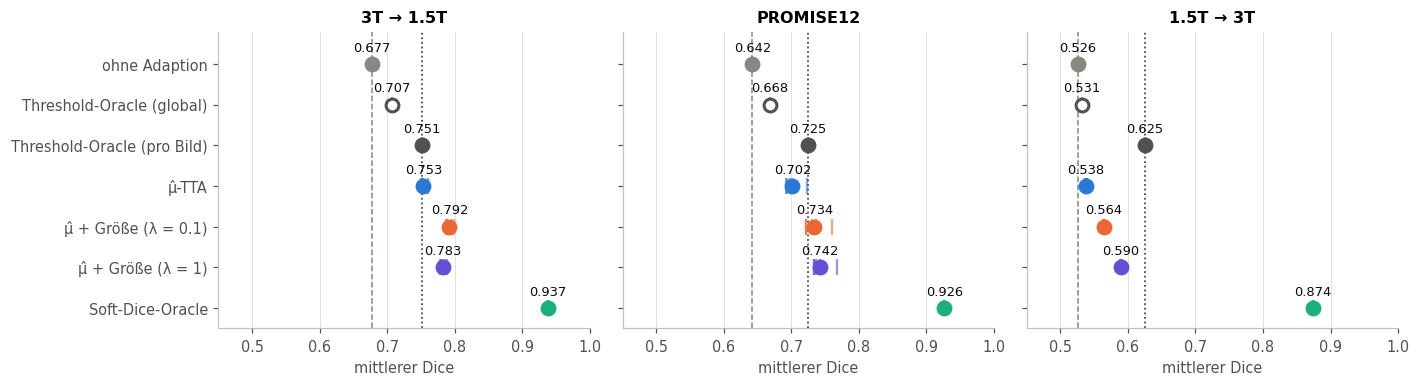

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
rows = ["Ausgang", "Threshold global", "Threshold-Oracle"] + MAIN
NAMES = {"Ausgang": "ohne Adaption", "Threshold global": "Threshold-Oracle (global)",
         "Threshold-Oracle": "Threshold-Oracle (pro Bild)"} | LABEL
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    r0 = R["mu", d, 0]
    base, thr = r0["dice_before"].mean(), r0["thr_oracle_dice"].mean()
    vals = {"Ausgang": [base], "Threshold-Oracle": [thr], "Threshold global": [r0["thr_global_dice"].mean()]}
    vals |= {v: per_pred(v, d, lambda r: r["dice_after"].mean()) for v in MAIN}
    ax.axvline(base, color=COL["Ausgang"], lw=1, ls="--")
    ax.axvline(thr, color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    for i, name in enumerate(rows):
        x = np.asarray(vals[name])
        ax.scatter(x, np.full(len(x), i), marker="|", s=120, color=COL[name], lw=1.5, alpha=0.6)
        hollow = name == "Threshold global"
        ax.scatter(x.mean(), i, s=70, edgecolor=COL[name], zorder=3, facecolor="white" if hollow else COL[name], lw=2)
        ax.text(x.mean(), i - 0.32, f"{x.mean():.3f}", ha="center", fontsize=8.5, color=INK)
    ax.set_title(dl); ax.set_xlim(0.45, 1.0); ax.set_xlabel("mittlerer Dice")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(rows)), [NAMES[r] for r in rows])
axes[0].set_ylim(len(rows) - 0.5, -0.8)
plt.tight_layout(); show(fig, "01_ueberblick")

Die Zahlen dazu. *verbessert / geschädigt*: Anteil der Fälle mit Δ Dice > +0.05 bzw. < −0.05.
*μ̂ − Dice nachher*: wie stark der Head am Ende überschätzt.

**Einordnung:**
- Die Gewinne sind über die Predictoren stabil (Std ≤ 0.014), d. h. jeder der 5 Predictoren
  profitiert.
- Auf 3T → 1.5T und PROMISE12 sinkt der Anteil geschädigter Fälle deutlich (11.4 % → 2.5 % bzw.
  5.4 % → 3.2 %). Auf 1.5T → 3T steigt er von 2.7 % auf 5.2 %, dafür verbessern sich 32 % statt 9 %.
- λ = 0.1 ist auf 3T → 1.5T etwas besser (0.792), λ = 1 auf den anderen beiden. Ein λ für alles
  ist also nicht optimal, aber beide liegen klar über der μ̂-TTA.
- Die Überschätzung μ̂ − Dice wird kleiner (3T → 1.5T: +0.09 → +0.03): μ̂ steigt etwas weniger, der Dice mehr. Vermutlich verhindert der Größenterm,
  dass die Adaption μ̂ auf Kosten der Maske hochtreibt. Auf 1.5T → 3T bleibt sie mit
  +0.27 groß.

In [4]:
def summary(v, d):
    d0, d1 = pooled(v, d, "dice_before"), pooled(v, d, "dice_after")
    dd = d1 - d0
    return {"Dice nachher": d1.mean(), "Δ Dice": dd.mean(),
            "Std über Predictoren": per_pred(v, d, lambda r: r["dice_after"].mean()).std(),
            "verbessert": (dd > TOL).mean(), "geschädigt": (dd < -TOL).mean(),
            "μ̂ − Dice nachher": (pooled(v, d, "mu_after") - d1).mean()}


tab = pd.DataFrame({(DOMAINS[d], LABEL[v]): summary(v, d) for d in DOMAINS for v in MAIN}).T
tab.index.names = ["Domäne", "Konfiguration"]
display(tab.style.format({"Dice nachher": "{:.3f}", "Δ Dice": "{:+.3f}", "Std über Predictoren": "{:.3f}",
                          "verbessert": "{:.1%}", "geschädigt": "{:.1%}", "μ̂ − Dice nachher": "{:+.3f}"}))
gap = {DOMAINS[d]: (tab.loc[(DOMAINS[d], LABEL["size1"]), "Dice nachher"] - tab.loc[(DOMAINS[d], LABEL["mu"]), "Dice nachher"])
       / (tab.loc[(DOMAINS[d], LABEL["oracle"]), "Dice nachher"] - tab.loc[(DOMAINS[d], LABEL["mu"]), "Dice nachher"])
       for d in DOMAINS}
print("Anteil der Lücke μ̂-TTA → Soft-Dice-Oracle, den λ = 1 schließt:", {k: f"{x:.0%}" for k, x in gap.items()})

Anteil der Lücke μ̂-TTA → Soft-Dice-Oracle, den λ = 1 schließt: {'3T → 1.5T': '16%', 'PROMISE12': '18%', '1.5T → 3T': '15%'}


## 2 · Unter- und Übersegmentierung

**Aussage:** Ohne Adaption ist FN deutlich größer als FP, die Masken sind also meist zu klein. Mit
dem Größenterm (λ = 1) sind FP und FN danach fast gleich groß. Der verbleibende Fehler ist dann kein
Größenfehler mehr, sondern ein Lagefehler: Die Maske ist richtig groß, sitzt aber teilweise an der
falschen Stelle.

*Lesen:* Mittlere Pixelzahl pro Bild (alle Fälle, alle Predictoren). Hell: FP (zu viel), dunkel:
FN (zu wenig). Im Titel die mittlere echte Prostatagröße |G|.

Auf 3T → 1.5T sinkt FN von 1590 auf 796 Pixel, FP steigt von 653 auf 804. In der Summe sind es also
deutlich weniger Fehlerpixel, aber FP nimmt zu: Die Maske wächst nicht nur dort, wo Prostata fehlt.
Auf 1.5T → 3T ändert sich die Summe kaum (3690 → 3425).

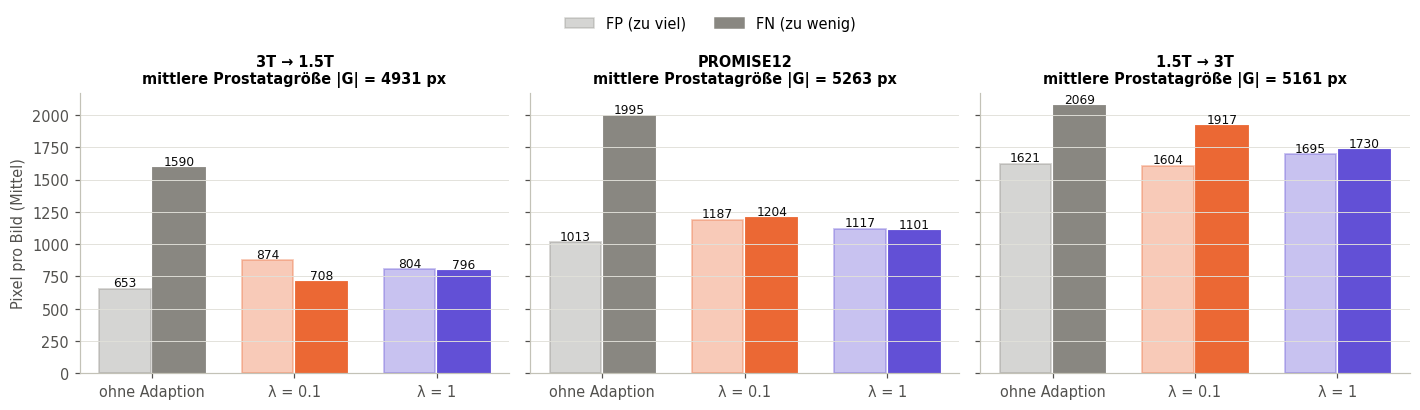

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
groups = [("vorher", None), (LABEL["size0.1"], "size0.1"), (LABEL["size1"], "size1")]
w = 0.36
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for i, (gl, v) in enumerate(groups):
        src = v or "size1"
        fp = pooled(src, d, "fp_before" if v is None else "fp_after").mean()
        fn = pooled(src, d, "fn_before" if v is None else "fn_after").mean()
        c = COL["Ausgang"] if v is None else COL[v]
        ax.bar(i - w / 2 - 0.01, fp, width=w, color=c, alpha=0.35, edgecolor=c, lw=1.2)
        ax.bar(i + w / 2 + 0.01, fn, width=w, color=c, edgecolor=c, lw=1.2)
        ax.text(i - w / 2 - 0.01, fp + 20, f"{fp:.0f}", ha="center", fontsize=8, color=INK)
        ax.text(i + w / 2 + 0.01, fn + 20, f"{fn:.0f}", ha="center", fontsize=8, color=INK)
    g = pooled("size1", d, "size_gt").mean()
    ax.set_title(f"{dl}\nmittlere Prostatagröße |G| = {g:.0f} px", fontsize=9.5)
    ax.set_xticks(range(len(groups)), ["ohne Adaption", "λ = 0.1", "λ = 1"])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Pixel pro Bild (Mittel)")
fig.legend(handles=[Patch(facecolor=MUTED, alpha=0.35, edgecolor=MUTED, label="FP (zu viel)"),
                    Patch(facecolor=MUTED, edgecolor=MUTED, label="FN (zu wenig)")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(rect=(0, 0, 1, 0.95)); show(fig, "02_fp_fn")

Wie gut stimmt die Größe pro Bild? Verteilung von log₂(|P| / |G|) vor und nach der Adaption
(0 = richtige Größe, −1 = halb so groß). Gestrichelt: Median.

**Einordnung:** Auf 3T → 1.5T und PROMISE12 sind die Masken vorher im Median zu klein und die
Verteilung ist breit. Danach liegt fast alles nahe 0. Auf 1.5T → 3T ist der Median vorher schon
etwa richtig, aber die Streuung ist in *beide* Richtungen groß (viele Totalausfälle links, viele
deutlich zu große Masken rechts). Hier hilft das Signal pro Bild, auch wenn es im Mittel nichts zu
korrigieren gibt. Nach der Adaption sind die Masken dort im Median etwas zu groß.

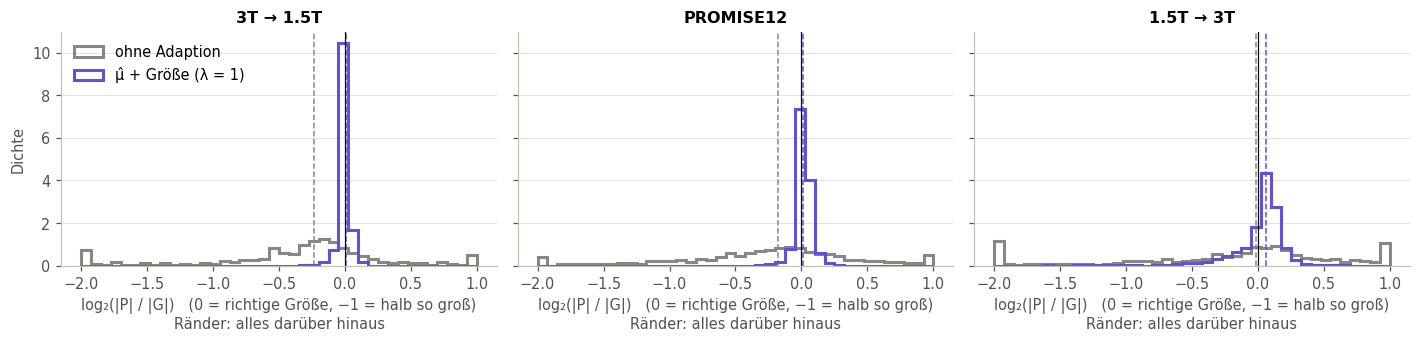

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
bins = np.linspace(-2, 1, 41)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    g = np.maximum(pooled("size1", d, "size_gt"), 1)
    for key, v, lab in (("size_before", "size1", "ohne Adaption"), ("size_after", "size1", LABEL["size1"])):
        # clipped: empty masks (log2 → −12) and gross over-segmentation pile up at the edges
        ratio = np.clip(np.log2(np.maximum(pooled(v, d, key), 1) / g), bins[0] + 1e-6, bins[-1] - 1e-6)
        c = COL["Ausgang"] if key == "size_before" else COL[v]
        ax.hist(ratio, bins=bins, histtype="step", lw=2, color=c, density=True, label=lab)
        ax.axvline(np.median(ratio), color=c, lw=1, ls="--")
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(dl); ax.set_xlabel("log₂(|P| / |G|)   (0 = richtige Größe, −1 = halb so groß)\nRänder: alles darüber hinaus")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Dichte"); axes[0].legend(loc="upper left")
plt.tight_layout(); show(fig, "02b_groessenverhaeltnis")

## 3 · Wo hilft die Größe?

**Aussage:** Der Größenterm hilft in fast allen Gruppen des Ausgangs-Dice, am meisten bei den
mittleren Fällen (0.25–0.75). Bei den Totalausfällen auf 1.5T → 3T (Dice < 0.25, 31 % der Fälle)
bringt die μ̂-TTA nichts (+0.00), mit Größe gibt es zumindest +0.07.

*Lesen:* Mittleres Δ Dice gegenüber ohne Adaption, gruppiert nach dem Dice vor der Adaption. n ist
die Fallzahl pro Predictor.

Ausnahme: Die Totalausfälle auf 3T → 1.5T gewinnen mit λ = 1 weniger als mit der μ̂-TTA allein
(+0.24 vs. +0.27). Dort ist die Maske oft an der falschen Stelle; die Zielgröße zieht dann eine falsch
platzierte Maske auf die richtige Größe, statt sie zu verschieben.

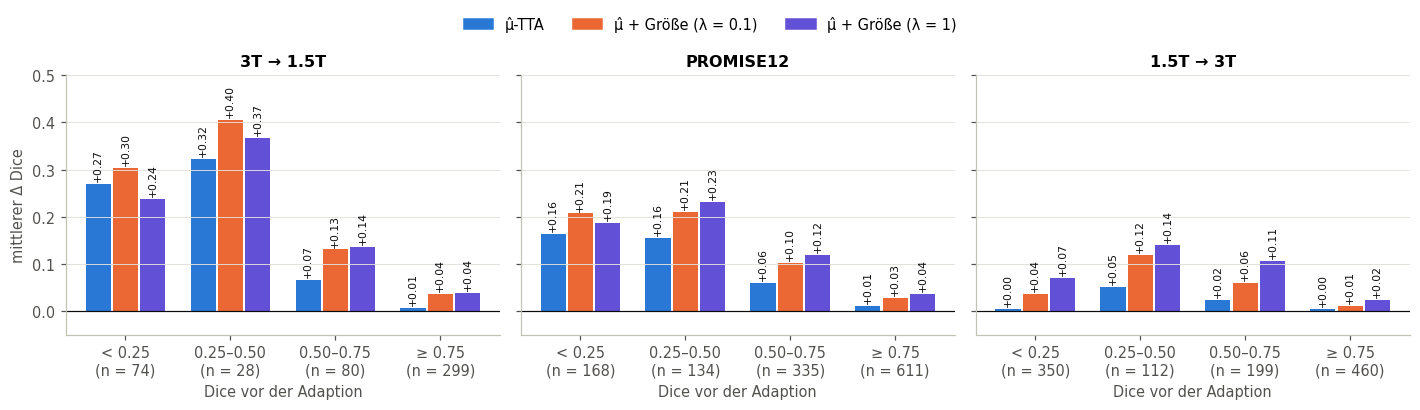

In [7]:
BINS = [(0, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 1.01)]
BIN_LAB = ["< 0.25", "0.25–0.50", "0.50–0.75", "≥ 0.75"]
CMP = ["mu", "size0.1", "size1"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
w = 0.26
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    d0 = pooled("mu", d, "dice_before")
    for j, v in enumerate(CMP):
        dd = pooled(v, d, "dice_after") - pooled(v, d, "dice_before")
        for i, (a, b) in enumerate(BINS):
            m = dd[(d0 >= a) & (d0 < b)].mean()
            x = i + (j - 1) * w
            ax.bar(x, m, width=w * 0.92, color=COL[v], label=LABEL[v] if i == 0 else None)
            ax.text(x, m + 0.006, f"{m:+.2f}", ha="center", fontsize=7, rotation=90, va="bottom", color=INK)
    n = [int(((d0 >= a) & (d0 < b)).sum() / len(PREDICTORS)) for a, b in BINS]
    ax.set_xticks(range(len(BINS)), [f"{l}\n(n = {k})" for l, k in zip(BIN_LAB, n)])
    ax.set_title(dl); ax.set_xlabel("Dice vor der Adaption"); ax.grid(axis="x", visible=False)
    ax.axhline(0, color=INK, lw=0.8)
axes[0].set_ylabel("mittlerer Δ Dice"); axes[0].set_ylim(-0.05, 0.5)
fig.legend(handles=[Patch(color=COL[v], label=LABEL[v]) for v in CMP], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(rect=(0, 0, 1, 0.95)); show(fig, "03_gewinn_nach_ausgang")

Anteil der Fälle, die besser, gleich oder schlechter werden (Schwelle ±0.05 Dice):

**Einordnung:** Auf 3T → 1.5T und PROMISE12 ist der Größenterm vor allem ein Schutz: Es gibt viel
weniger geschädigte Fälle als mit der μ̂-TTA. Auf 1.5T → 3T verbessert er vor allem mehr Fälle,
schadet aber auch etwas mehr.

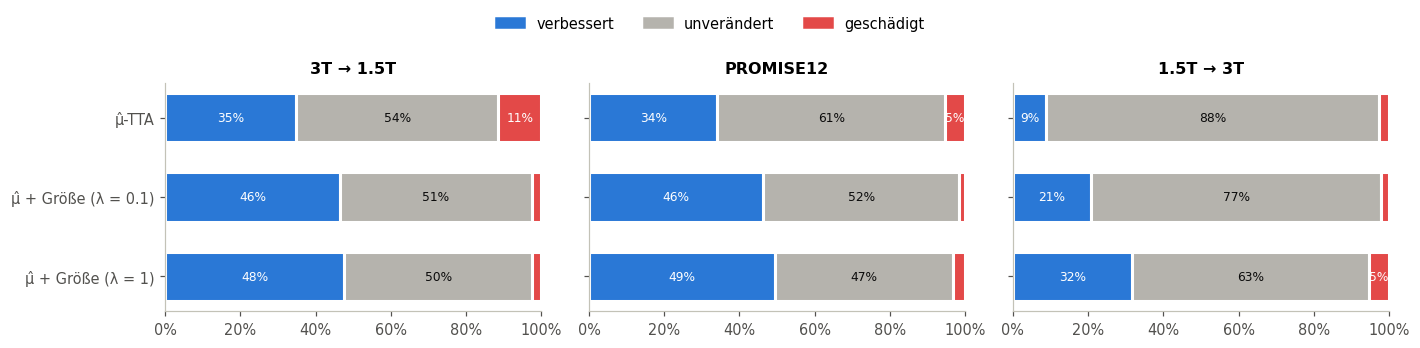

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.0), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for i, v in enumerate(CMP):
        dd = pooled(v, d, "dice_after") - pooled(v, d, "dice_before")
        parts = {"verbessert": (dd > TOL).mean(), "unverändert": (np.abs(dd) <= TOL).mean(), "geschädigt": (dd < -TOL).mean()}
        left = 0
        for k, x in parts.items():
            ax.barh(i, x, left=left, color=GROUP_COL[k], height=0.62, edgecolor="white", lw=2)
            if x > 0.04:
                ax.text(left + x / 2, i, f"{x:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if k != "unverändert" else INK)
            left += x
    ax.set_title(dl); ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1); ax.grid(visible=False)
axes[0].set_yticks(range(len(CMP)), [LABEL[v] for v in CMP]); axes[0].invert_yaxis()
fig.legend(handles=[Patch(color=c, label=k) for k, c in GROUP_COL.items()], loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(rect=(0, 0, 1, 0.93)); show(fig, "03b_verbessert_geschaedigt")

## 4 · Pro Fall: Größe vs. μ̂-TTA

**Aussage:** Pro Fall ist λ = 1 in etwa der Hälfte der Fälle besser als die μ̂-TTA (58 / 55 / 47 %)
und in 12–16 % schlechter. Der Gewinn ist also kein Effekt weniger Ausreißer.

*Lesen:* Jeder Punkt ist ein Fall eines Predictors. x: Δ Dice der μ̂-TTA, y: Δ Dice mit Größe.
Über der Diagonale hilft die Größe zusätzlich. Auf 1.5T → 3T liegen die Punkte fast senkrecht über
x = 0: Die μ̂-TTA bewegt dort die Maske kaum, erst der Größenterm verändert etwas, in beide
Richtungen.

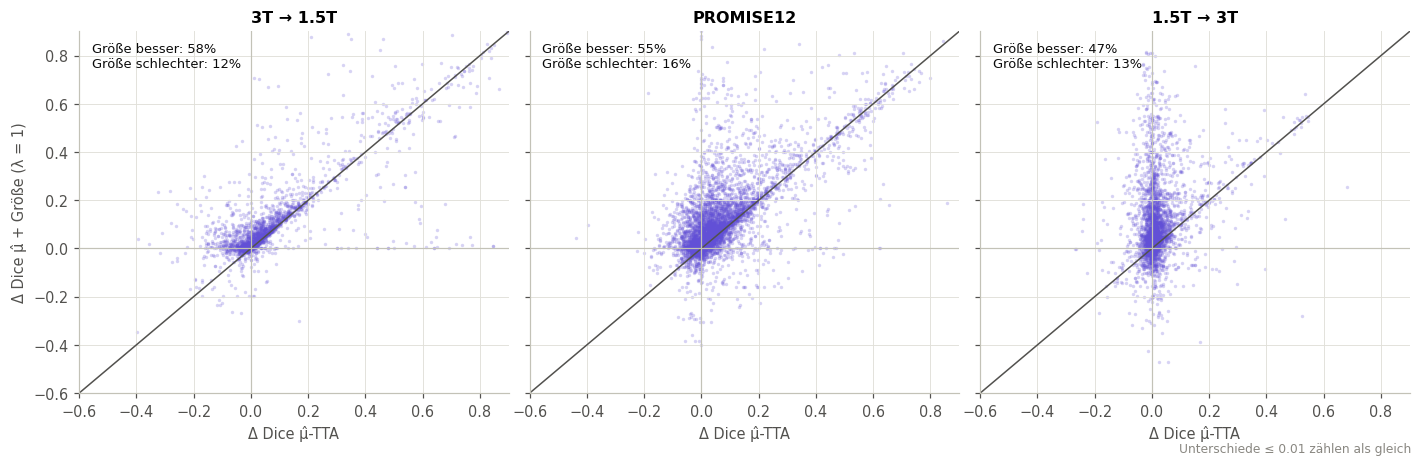

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    d0 = pooled("mu", d, "dice_before")
    a = pooled("mu", d, "dice_after") - d0
    b = pooled("size1", d, "dice_after") - d0
    ax.scatter(a, b, s=5, color=COL["size1"], alpha=0.25, lw=0)
    ax.plot([-1, 1], [-1, 1], color=INK2, lw=1)
    ax.axhline(0, color=AXIS, lw=0.8); ax.axvline(0, color=AXIS, lw=0.8)
    above, below = (b > a + 0.01).mean(), (b < a - 0.01).mean()
    ax.text(0.03, 0.97, f"Größe besser: {above:.0%}\nGröße schlechter: {below:.0%}", transform=ax.transAxes,
            va="top", fontsize=8.5, color=INK)
    ax.set_title(dl); ax.set_xlabel("Δ Dice μ̂-TTA"); ax.set_xlim(-0.6, 0.9); ax.set_ylim(-0.6, 0.9)
axes[0].set_ylabel("Δ Dice μ̂ + Größe (λ = 1)")
fig.text(0.99, 0.01, "Unterschiede ≤ 0.01 zählen als gleich", ha="right", fontsize=8, color=MUTED)
plt.tight_layout(); show(fig, "04_pro_fall")

## 5 · Verlauf über die Schritte

**Aussage:** Der Größenfehler fällt schnell (λ = 1: in ~30 Schritten unter 5 % auf 3T → 1.5T und
PROMISE12). Der Dice steigt mit und flacht nicht so früh ab wie bei der μ̂-TTA. Mit λ = 0.1 ist der
Größenterm zu schwach, um die Größe in 100 Schritten zu erreichen (am Ende noch 4 / 12 / 19 % Fehler).

*Lesen:* Oben: durchgezogen der echte Dice, gestrichelt μ̂, gemittelt über alle Fälle und
Predictoren; die Zahl am Ende ist μ̂ − Dice nach 100 Schritten. Unten: Median des relativen
Größenfehlers |P − G| / G der harten Maske.

**Einordnung:** Auf 3T → 1.5T fällt der Dice der μ̂-TTA nach ~60 Schritten wieder leicht ab, mit
Größenterm nicht. Das passt zum Stopping-Problem aus dem letzten Treffen: Ein Signal mit festem Anker
(Zielgröße) verhindert, dass die Adaption davonläuft, μ̂ allein tut das nicht. Auf 1.5T → 3T bleibt
der Größenfehler bei ~7 %, d. h. der μ̂-Term zieht dort gegen die Größe.

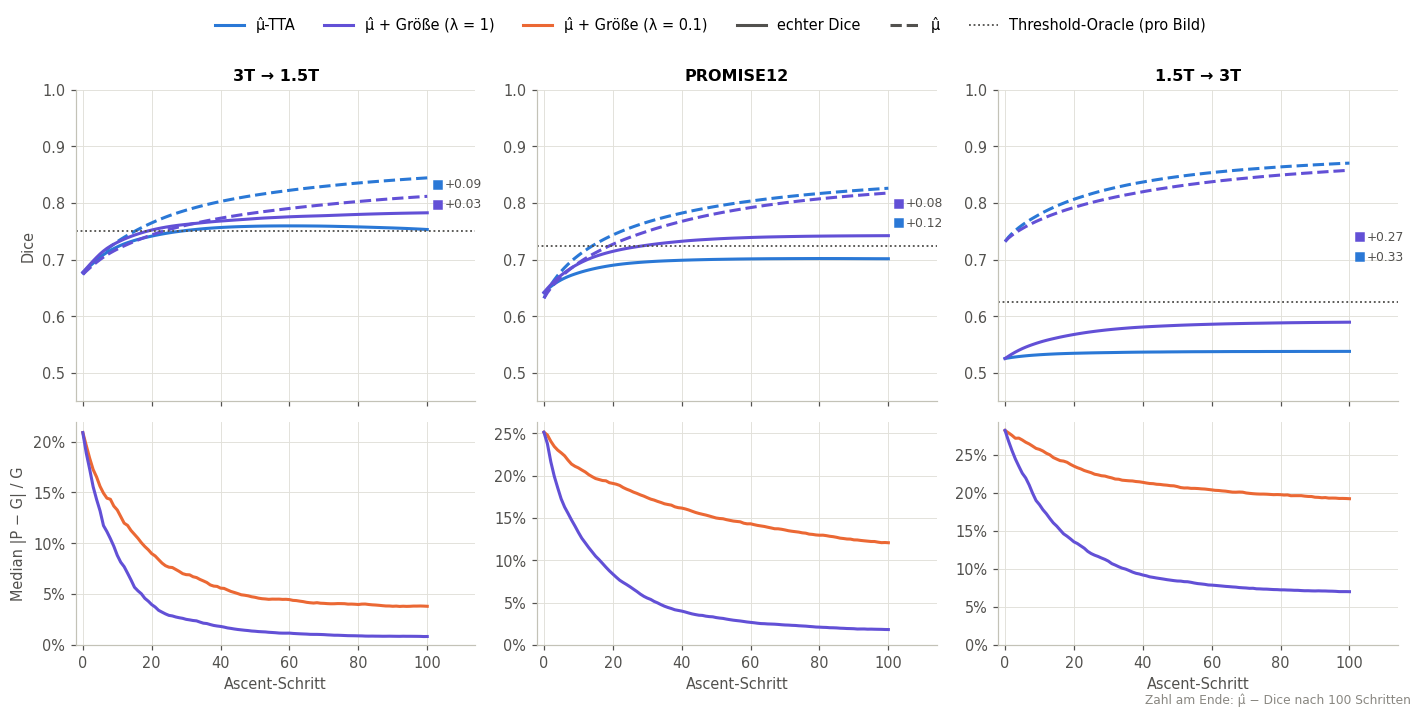

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
for k, (d, dl) in enumerate(DOMAINS.items()):
    ax, ax2 = axes[0, k], axes[1, k]
    labels = []
    for v in ["mu", "size1"]:
        dice, mu = pooled(v, d, "dice_per_step").mean(0), pooled(v, d, "mu_per_step").mean(0)
        ax.plot(dice, color=COL[v]); ax.plot(mu, color=COL[v], ls="--")
        labels.append([(mu[-1] + dice[-1]) / 2, mu[-1] - dice[-1], COL[v]])
    labels.sort(key=lambda l: l[0])
    for a, b in zip(labels, labels[1:]):
        b[0] = max(b[0], a[0] + 0.035)
    for y, gap, c in labels:
        ax.plot(103, y, marker="s", ms=5, color=c, clip_on=False)
        ax.text(105, y, f"{gap:+.2f}", fontsize=8, color=INK2, va="center")
    ax.axhline(R["mu", d, 0]["thr_oracle_dice"].mean(), color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    ax.set_title(dl); ax.set_ylim(0.45, 1.0); ax.set_xlim(-2, 114)
    for v in SIZE:
        g = np.maximum(pooled(v, d, "size_gt"), 1)[:, None]
        rel = np.abs(pooled(v, d, "hard_size_per_step") - g) / g
        ax2.plot(np.median(rel, 0), color=COL[v], label=LABEL[v])
    ax2.set_xlabel("Ascent-Schritt"); ax2.set_ylim(0, None)
axes[0, 0].set_ylabel("Dice"); axes[1, 0].set_ylabel("Median |P − G| / G")
axes[1, 0].yaxis.set_major_formatter(PCT)
for a in axes[1]: a.yaxis.set_major_formatter(PCT)
handles = [Line2D([], [], color=COL[v], label=LABEL[v]) for v in ["mu", "size1", "size0.1"]]
handles += [Line2D([], [], color=INK2, label="echter Dice"), Line2D([], [], color=INK2, ls="--", label="μ̂"),
            Line2D([], [], color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS, label="Threshold-Oracle (pro Bild)")]
plt.tight_layout(rect=(0, 0, 1, 0.93))
fig.legend(handles=handles, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.0))
fig.text(0.99, 0.005, "Zahl am Ende: μ̂ − Dice nach 100 Schritten", ha="right", fontsize=8, color=MUTED)
show(fig, "05_verlauf")

## 6 · Rauschen auf FP und FN (Run C)

**Aussage:** Mit verrauschtem FP₀ und FN₀ (bis ±30 %) bleibt der Dice praktisch gleich: höchstens
−0.003 gegenüber dem exakten Oracle, auf allen Shifts noch klar über der μ̂-TTA.

*Lesen:* Mittlerer Dice mit λ = 1 abhängig von der Rauschstärke n (ε ~ U(−n, n), unabhängig für FP
und FN, pro Bild gezogen). Kleine Striche: die 5 Predictoren. Gestrichelte Linien: μ̂-TTA, ohne
Adaption und Threshold-Oracle pro Bild.

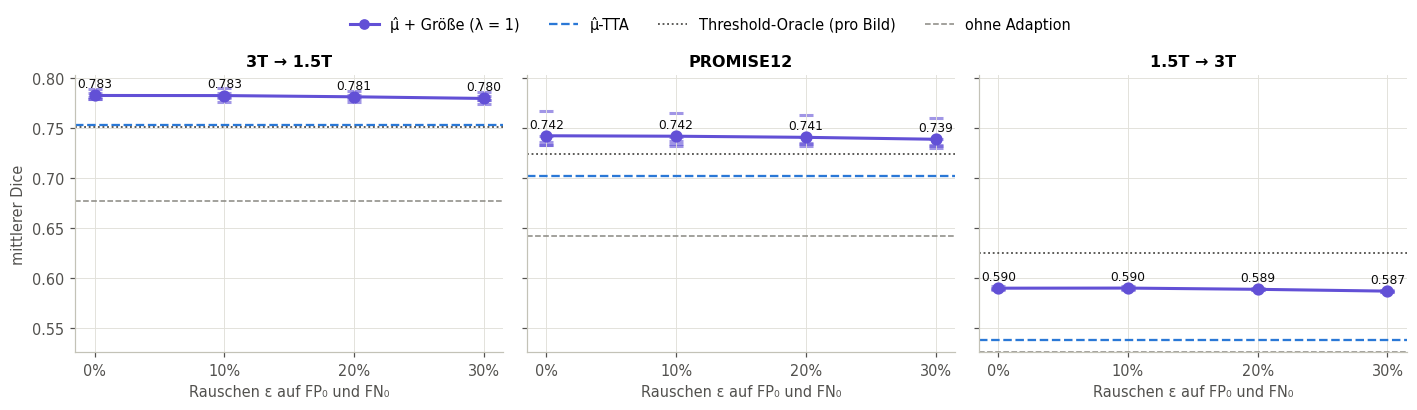

In [11]:
eps_levels = sorted(NOISE)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    m = [per_pred(NOISE[e], d, lambda r: r["dice_after"].mean()) for e in eps_levels]
    ax.plot(eps_levels, [x.mean() for x in m], color=COL["size1"], marker="o", ms=7, label=LABEL["size1"])
    for e, x in zip(eps_levels, m):
        ax.scatter(np.full(len(x), e), x, marker="_", s=80, color=COL["size1"], alpha=0.6)
        ax.text(e, x.mean() + 0.008, f"{x.mean():.3f}", ha="center", fontsize=8, color=INK)
    ax.axhline(per_pred("mu", d, lambda r: r["dice_after"].mean()).mean(), color=COL["mu"], lw=1.5, ls="--")
    ax.axhline(R["mu", d, 0]["thr_oracle_dice"].mean(), color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    ax.axhline(R["mu", d, 0]["dice_before"].mean(), color=COL["Ausgang"], lw=1, ls="--")
    ax.set_title(dl); ax.set_xlabel("Rauschen ε auf FP₀ und FN₀"); ax.xaxis.set_major_formatter(PCT)
    ax.set_xticks(eps_levels)
axes[0].set_ylabel("mittlerer Dice")
handles = [Line2D([], [], color=COL["size1"], marker="o", label="μ̂ + Größe (λ = 1)"),
           Line2D([], [], color=COL["mu"], ls="--", lw=1.5, label="μ̂-TTA"),
           Line2D([], [], color=COL["Threshold-Oracle"], ls=THR_LS, lw=1.2, label="Threshold-Oracle (pro Bild)"),
           Line2D([], [], color=COL["Ausgang"], ls="--", lw=1, label="ohne Adaption")]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(rect=(0, 0, 1, 0.95)); show(fig, "06_rauschen")

Wichtig für die Interpretation: Wie falsch ist die Zielgröße Ĝ durch das Rauschen tatsächlich?

**Einordnung:** ±30 % auf FP₀ und FN₀ ergeben im Median nur 4–7 % Fehler auf Ĝ (90 %-Quantil
18–29 %). Grund: Der Fehler ist (−FP₀·ε_FP + FN₀·ε_FN) / |G|, FP₀ und FN₀ sind zusammen meist
deutlich kleiner als |G| und die beiden Fehler heben sich teilweise auf. Run C zeigt also vor allem,
dass ein paar Prozent Größenfehler nichts kosten. Für einen gelernten Head ist das relevant, weil ein
Fehler auf FP und FN viel weniger schadet als derselbe relative Fehler direkt auf |G|.

In [12]:
rows = {}
for d, dl in DOMAINS.items():
    for e in eps_levels:
        v = NOISE[e]
        g = np.maximum(pooled(v, d, "size_gt"), 1)
        err = (pooled(v, d, "size_target") - g) / g
        dd = pooled(v, d, "dice_after") - pooled(v, d, "dice_before")
        rows[(dl, f"{e:.0%}")] = {"Median |Ĝ − G| / G": np.median(np.abs(err)),
                                  "90 %-Quantil |Ĝ − G| / G": np.quantile(np.abs(err), 0.9),
                                  "Dice nachher": pooled(v, d, "dice_after").mean(),
                                  "geschädigt": (dd < -TOL).mean()}
t6 = pd.DataFrame(rows).T; t6.index.names = ["Domäne", "ε"]
display(t6.style.format({"Median |Ĝ − G| / G": "{:.1%}", "90 %-Quantil |Ĝ − G| / G": "{:.1%}",
                         "Dice nachher": "{:.3f}", "geschädigt": "{:.1%}"}))

Ab welchem Fehler der Zielgröße schadet der Größenterm? Alle Rausch-Runs (ε = 0 … 30 %) gepoolt, pro
Fall nach dem vorzeichenbehafteten Fehler (Ĝ − G) / G gruppiert; y ist der Gewinn gegenüber der
μ̂-TTA (gleicher Fall, gleicher Predictor).

**Einordnung:** Bis etwa ±8 % Fehler ist der Gewinn in allen drei Shifts stabil. Auf 3T → 1.5T kippt
er bei zu großer Zielgröße (> +8 %) ins Negative, auf PROMISE12 bei deutlich zu kleiner (< −15 %).
Vorsicht: Große Fehler kommen nur bei Fällen mit großem FP₀ oder FN₀ vor, also bei schlechten
Ausgangsmasken. Die Gruppen unterscheiden sich daher nicht nur im Fehler, sondern auch in der
Ausgangslage (deshalb z. B. der hohe Gewinn rechts auf 1.5T → 3T). Für eine saubere
Toleranzkurve bräuchte man Rauschen direkt auf |G| (siehe Abschnitt 8).

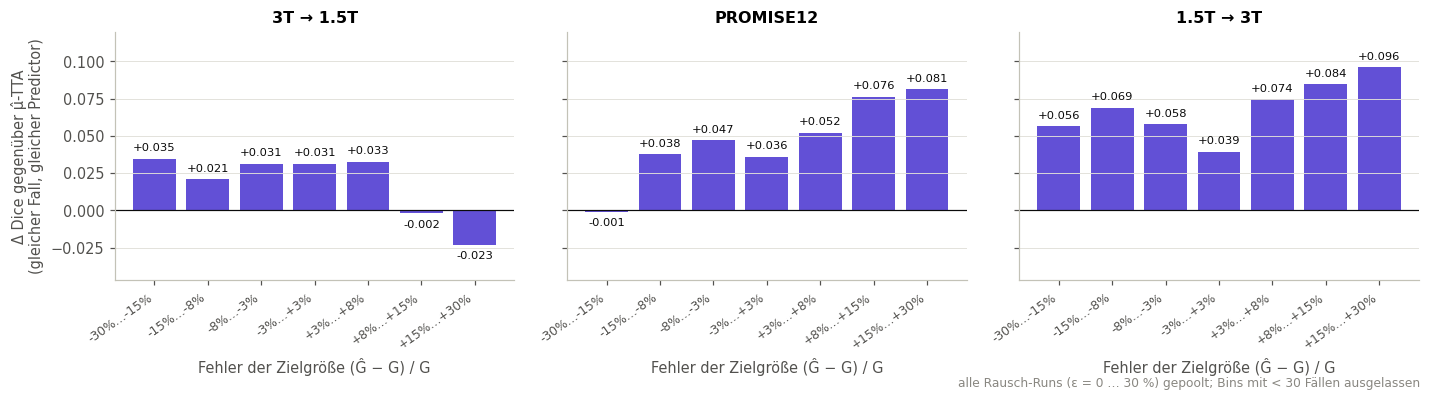

In [13]:
EDGES = np.array([-0.3, -0.15, -0.08, -0.03, 0.03, 0.08, 0.15, 0.3])
centers = (EDGES[:-1] + EDGES[1:]) / 2
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    vs = [NOISE[e] for e in eps_levels]
    g = np.concatenate([np.maximum(pooled(v, d, "size_gt"), 1) for v in vs])
    err = np.concatenate([pooled(v, d, "size_target") for v in vs]) / g - 1
    d1 = np.concatenate([pooled(v, d, "dice_after") for v in vs])
    d_mu = np.concatenate([pooled("mu", d, "dice_after") for _ in vs])   # same cases, same predictor
    gain = d1 - d_mu
    idx = np.digitize(err, EDGES) - 1
    ok = (idx >= 0) & (idx < len(centers))
    m = np.array([gain[ok & (idx == i)].mean() if (ok & (idx == i)).sum() >= 30 else np.nan for i in range(len(centers))])
    n = np.array([(ok & (idx == i)).sum() for i in range(len(centers))])
    ax.bar(np.arange(len(centers)), m, color=COL["size1"], width=0.8)
    for i, (x, k) in enumerate(zip(m, n)):
        if np.isfinite(x):
            ax.text(i, x + (0.004 if x >= 0 else -0.004), f"{x:+.3f}", ha="center", va="bottom" if x >= 0 else "top",
                    fontsize=7.5, color=INK)
    ax.axhline(0, color=INK, lw=0.8); ax.margins(y=0.2)
    ax.set_xticks(np.arange(len(centers)), [f"{a:+.0%}…{b:+.0%}" for a, b in zip(EDGES[:-1], EDGES[1:])],
                  rotation=35, ha="right", fontsize=8)
    ax.set_title(dl); ax.set_xlabel("Fehler der Zielgröße (Ĝ − G) / G"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Δ Dice gegenüber μ̂-TTA\n(gleicher Fall, gleicher Predictor)")
fig.text(0.99, 0.01, "alle Rausch-Runs (ε = 0 … 30 %) gepoolt; Bins mit < 30 Fällen ausgelassen", ha="right",
         fontsize=8, color=MUTED)
plt.tight_layout(); show(fig, "06b_toleranz")

## 7 · Beispiele: wo es funktioniert und wo nicht

Pro Shift sechs Fälle von Predictor 0, ausgewählt aus *allen* Testfällen:
- **gut:** die 2 Fälle mit dem größten Gewinn durch den Größenterm gegenüber der μ̂-TTA,
- **schlechter als μ̂-TTA:** die 2 Fälle mit dem größten Verlust gegenüber der μ̂-TTA,
- **schadet:** die 2 Fälle (ohne die vorigen), die gegenüber ohne Adaption am meisten verlieren.

Grün: richtig, rot: zu viel (FP), blau: fehlt (FN); Zahl im Titel: Dice. Die Hauptläufe speichern
nur 6 gleichmäßig verteilte Bilder pro Domäne, deshalb wurden diese Fälle mit denselben
Einstellungen noch einmal gerechnet.

**Aussage:** Alle hier gezeigten Fehlschläge haben dasselbe Muster. Die Maske besteht vorher aus zwei Teilen,
der Prostata und einer falschen Region daneben (Rektum, Blase, Gewebe außerhalb). Der Größenterm
erzwingt die richtige *Menge* an Pixeln, und μ̂ entscheidet, *welcher* Teil wächst oder schrumpft.
Bei den Fehlschlägen wählt μ̂ den falschen Teil:
- **Maske zu groß** (z. B. PROMISE12 Fall 136, 1.5T → 3T Fall 112 und 226): Die Maske wird auf die
  richtige Größe geschrumpft, aber die Prostata verschwindet und die falsche Region bleibt. Dice
  fällt auf ≈ 0.
- **Maske zu klein** (z. B. 3T → 1.5T Fall 199 und 65): Statt der Prostata wächst die falsche Region,
  während die μ̂-TTA allein die Prostata gefunden hätte (0.93 bzw. 0.79).

Die guten Fälle sind das Spiegelbild: Dort wächst die richtige Region. Die Größe sagt also nur, wie
viel, nicht wo, und wenn μ̂ die falsche Region bevorzugt, verstärkt der Größenterm den Fehler. Das
Soft-Dice-Oracle löst alle diese Fälle (0.71–0.95).

**Nebenbefund (Reproduzierbarkeit):** Beim Nachrechnen weichen einzelne Fälle mit μ̂ im Objective
deutlich ab (im Titel als „Hauptlauf“ markiert, z. B. 1.5T → 3T Fall 447: 0.18 statt 0.50). Gleiche
Einstellungen und gleiche Batches, der Unterschied kommt also nur von nicht-deterministischen
GPU-Rechnungen. Beim Soft-Dice-Oracle tritt das nicht auf (≤ 0.005). Bei solchen Fällen steht der
μ̂-Ascent offenbar an einer Kippstelle zwischen zwei Regionen; kleine numerische Unterschiede
entscheiden, welche gewinnt. Die Mittelwerte über ~500–1250 Fälle betrifft das kaum, einzelne Fälle
aber stark.

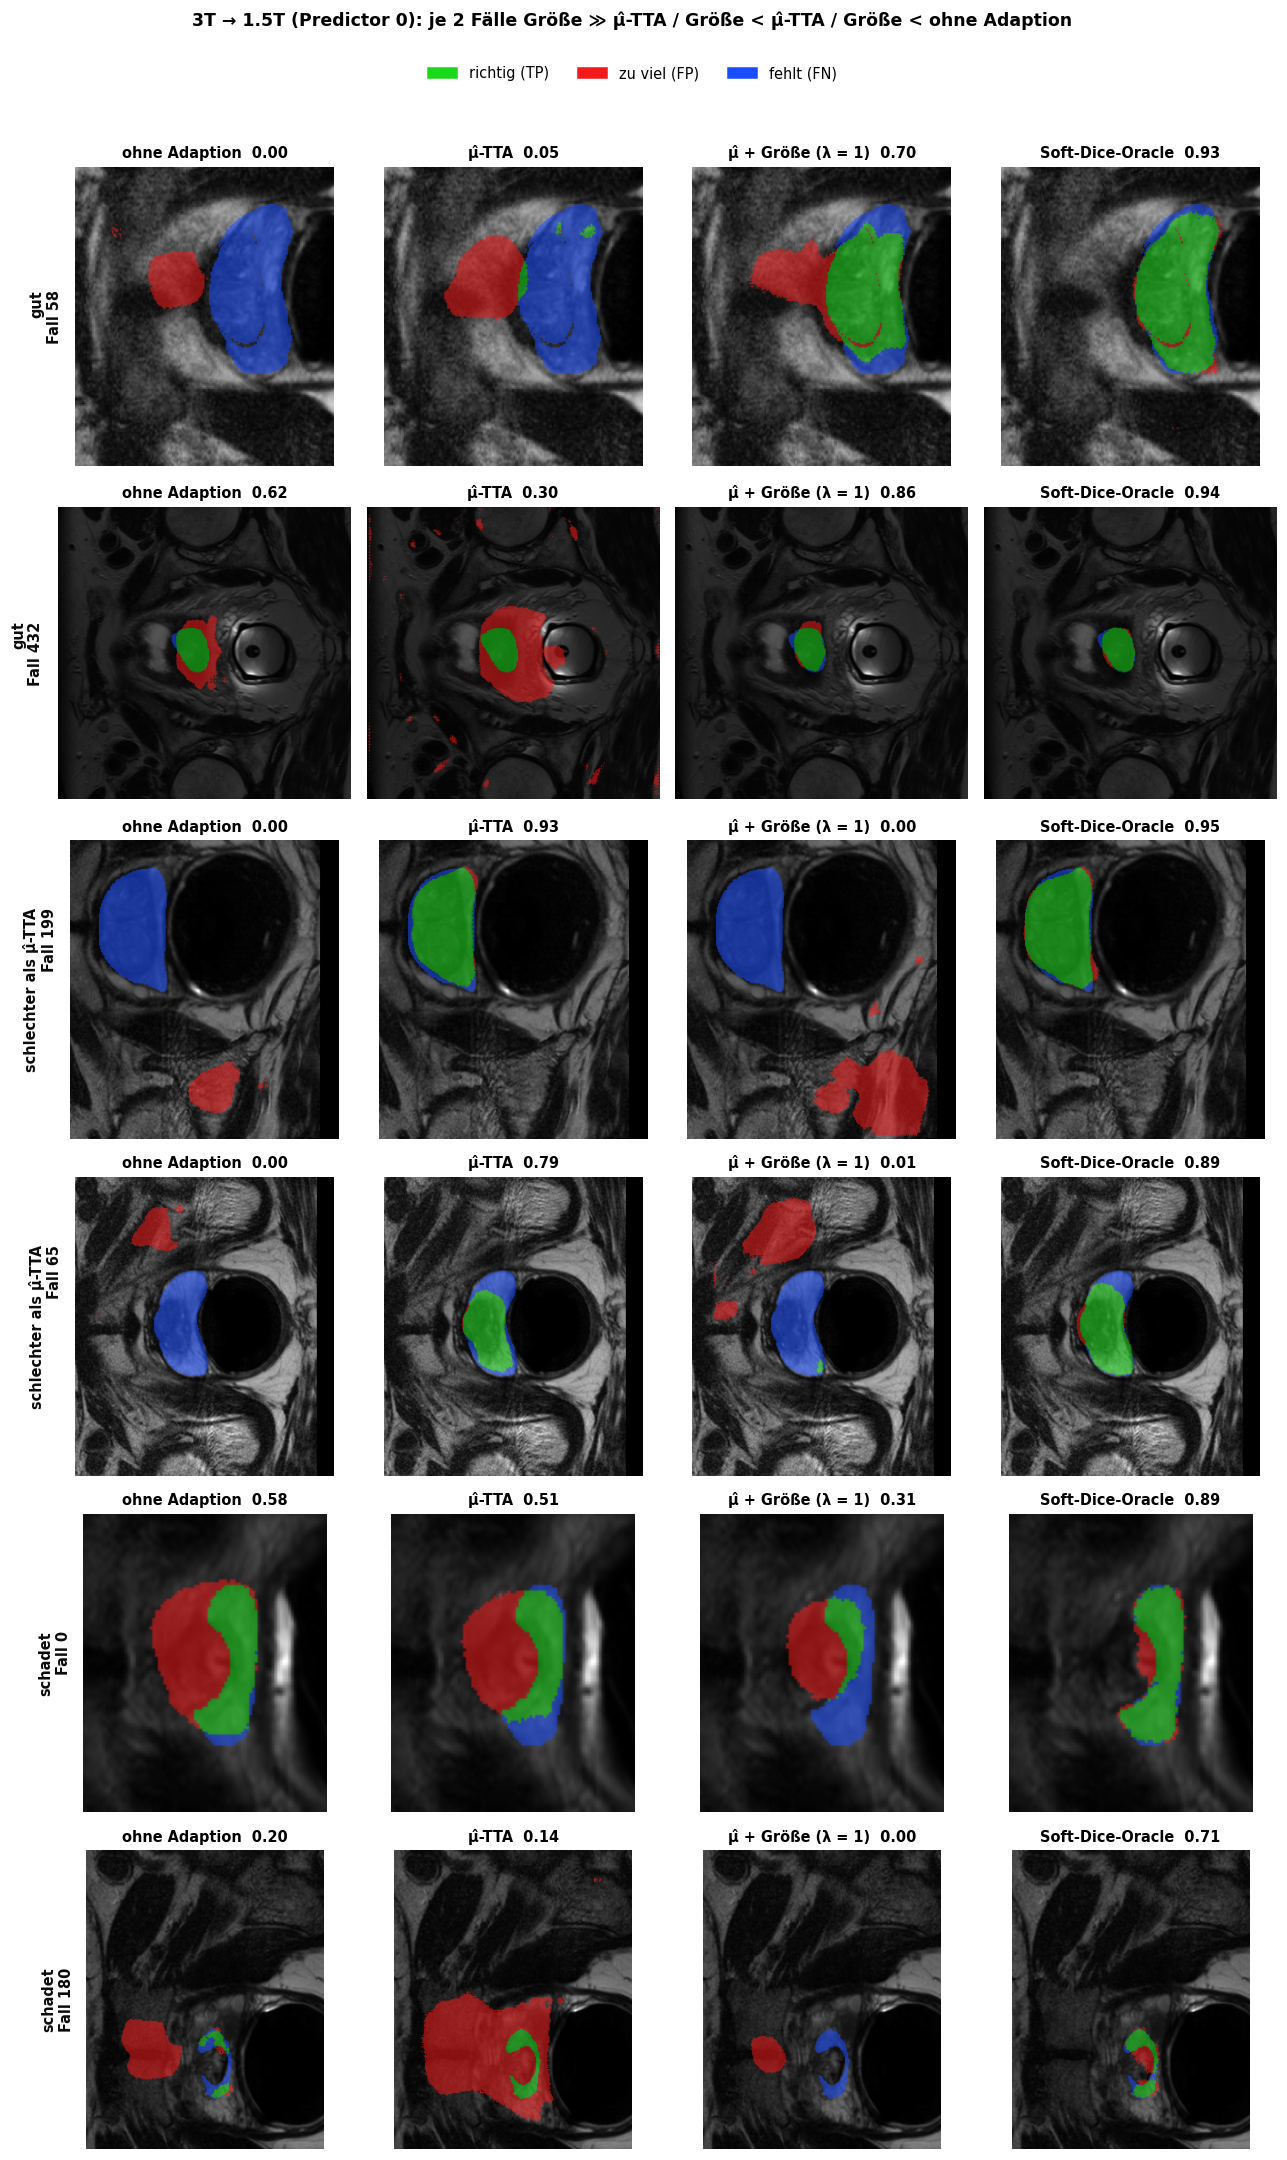

3T → 1.5T: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei keinem Fall


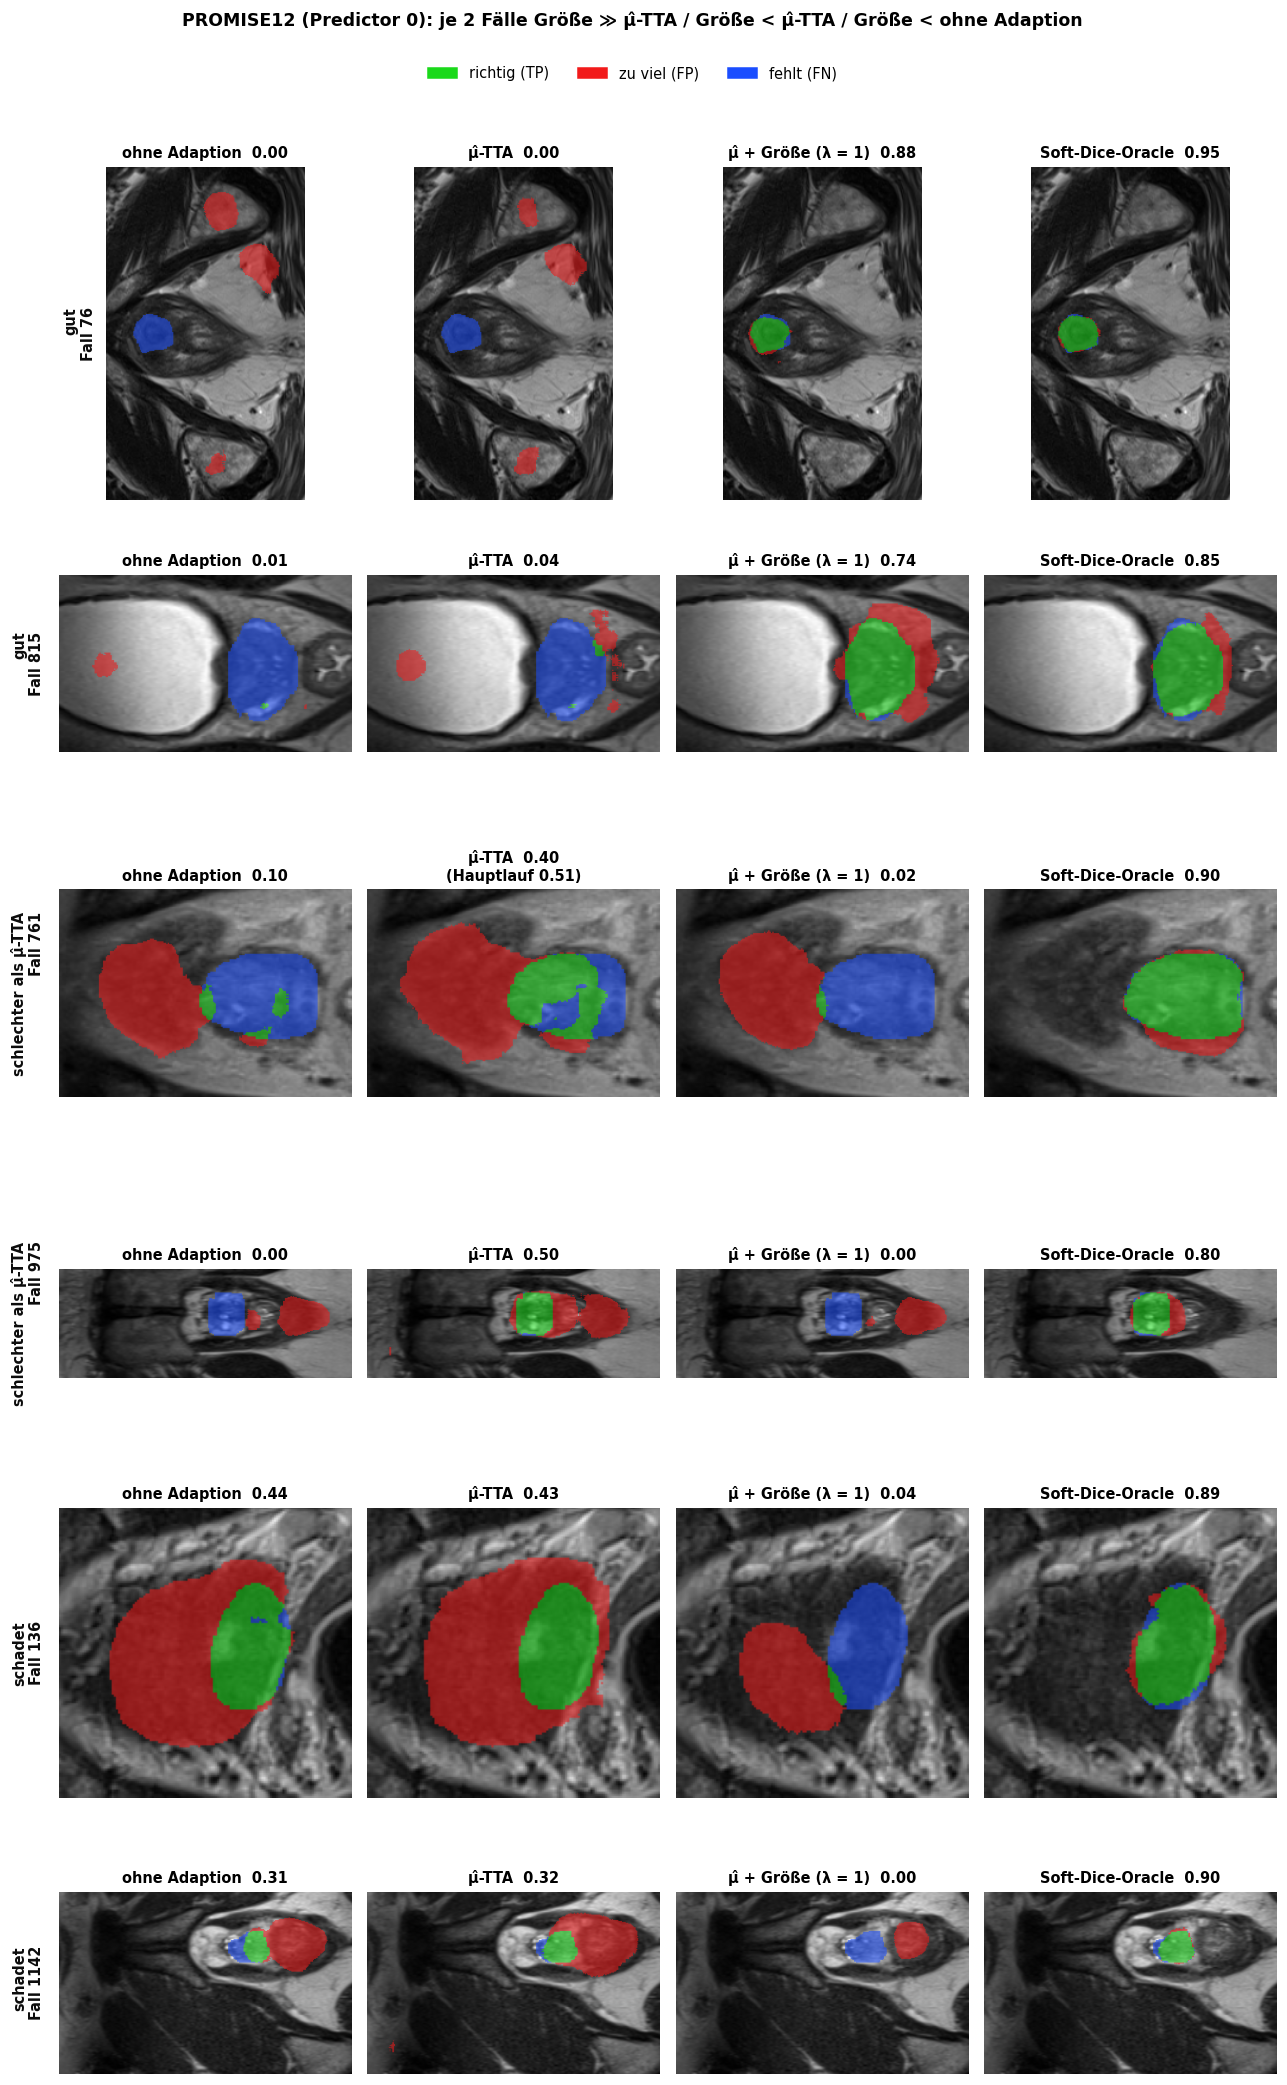

PROMISE12: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei Fall 761 μ̂-TTA (0.40 statt 0.51)


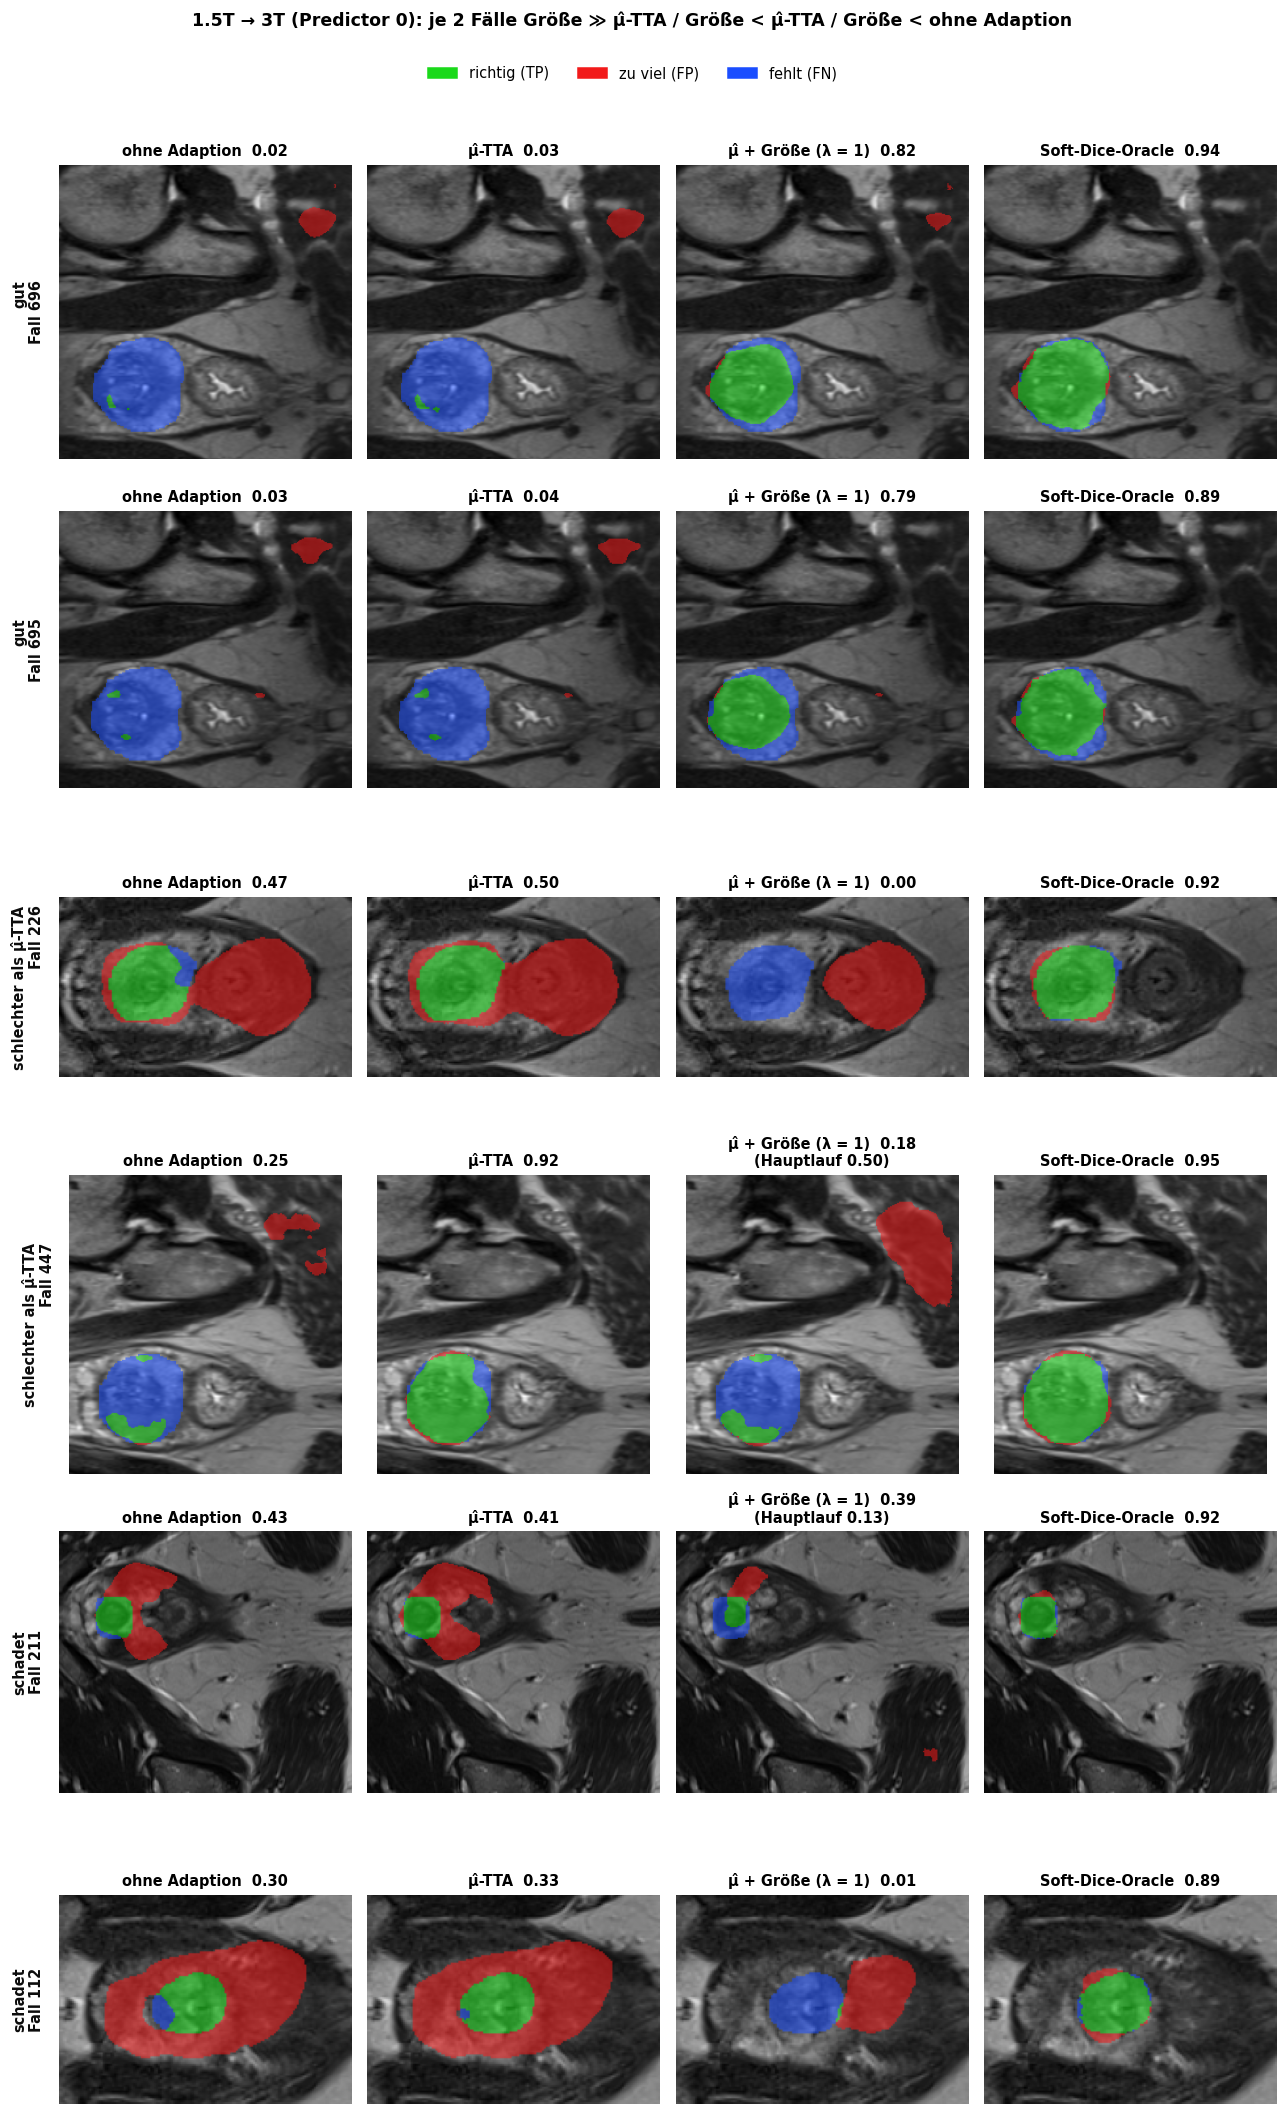

1.5T → 3T: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei Fall 447 μ̂ + Größe (λ = 1) (0.18 statt 0.50), Fall 211 μ̂ + Größe (λ = 1) (0.39 statt 0.13)


In [14]:
# the cases are chosen from ALL test cases of predictor 0 and re-run with the same settings
# (tta.example_indices + tta.examples_only, src/apps/eval_latent_tta.py): the main runs only
# store 6 evenly spaced snapshots per domain
SHOW = ["mu", "size1", "oracle"]
EX_RUNS = {"mu": "latent_tta_examples_mu", "size1": "latent_tta_examples_size_w1.0",
           "oracle": "latent_tta_examples_oracle"}
GROUPS = [("gut", "Größe ≫ μ̂-TTA"), ("schlechter als μ̂-TTA", "Größe < μ̂-TTA"),
          ("schadet", "Größe < ohne Adaption")]


def select_cases(d, k=2):
    dm, ds = R["mu", d, 0]["dice_after"], R["size1", d, 0]["dice_after"]
    d0 = R["mu", d, 0]["dice_before"]
    good = list(np.argsort(-(ds - dm))[:k])
    worse = list(np.argsort(ds - dm)[:k])
    harmed = [i for i in np.argsort(ds - d0) if i not in good + worse][:k]
    return [int(i) for i in good + worse + harmed]


def hard_dice(p, g):
    p, g = p > 0, g > 0
    return 2 * (p & g).sum() / max(p.sum() + g.sum(), 1)


NAMES7 = ["ohne Adaption", "μ̂-TTA", "μ̂ + Größe (λ = 1)", "Soft-Dice-Oracle"]


def example_panel(d, k=2, show_v=SHOW, ex_runs=EX_RUNS, names=NAMES7, select=select_cases, groups=GROUPS,
                  fname="07_beispiele"):
    cases = select(d, k)
    ex = {v: load(f, d, 0)["examples"] for v, f in ex_runs.items()}
    pos = {v: {int(i): j for j, i in enumerate(ex[v]["index"])} for v in show_v}
    assert all(set(cases) <= set(pos[v]) for v in show_v), "re-run the example cases (logs/examples_*.log)"
    fig, axes = plt.subplots(len(cases), len(names), figsize=(3 * len(names), 3.2 * len(cases)))
    dev = []
    for row, i in enumerate(cases):
        e = {v: {key: ex[v][key][pos[v][i]] for key in ex[v]} for v in show_v}
        img, gt = e["mu"]["image"], e["mu"]["target"]
        preds = [e["mu"]["pred_before"]] + [e[v]["pred_final"] for v in show_v]
        dice = [hard_dice(p, gt) for p in preds]
        # Dice of the main runs (selection) next to the re-run (image) where they differ
        main = [R["mu", d, 0]["dice_before"][i]] + [R[v, d, 0]["dice_after"][i] for v in show_v]
        dev += [(i, n, dc, m) for n, dc, m in zip(names, dice, main) if abs(dc - m) > 0.05]
        crop = _crop_box([gt] + preds, gt.shape)
        for ax, p, t, dc, m in zip(axes[row], preds, names, dice, main):
            note = f"\n(Hauptlauf {m:.2f})" if abs(dc - m) > 0.05 else ""
            ax.imshow(_overlay(img, gt, p)[crop]); ax.set_title(f"{t}  {dc:.2f}{note}", fontsize=9.5); ax.axis("off")
        group, rule = groups[row // k]
        axes[row, 0].text(-0.05, 0.5, f"{group}\nFall {i}", transform=axes[row, 0].transAxes, rotation=90,
                          ha="right", va="center", fontsize=9.5, color=INK, fontweight="bold")
    handles = [Patch(color=c, label=l) for c, l in (((0.1, 0.85, 0.1), "richtig (TP)"), ((0.95, 0.1, 0.1), "zu viel (FP)"),
                                                     ((0.1, 0.3, 1.0), "fehlt (FN)"))]
    fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f"{DOMAINS[d]} (Predictor 0): je 2 Fälle {' / '.join(r for _, r in groups)}", y=1.02,
                 fontweight="bold")
    plt.tight_layout(rect=(0.02, 0, 1, 0.98)); show(fig, f"{fname}_{d}")
    print(f"{DOMAINS[d]}: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei",
          ", ".join(f"Fall {i} {n} ({dc:.2f} statt {m:.2f})" for i, n, dc, m in dev) or "keinem Fall")


for d in DOMAINS:
    example_panel(d)

## 8 · FP/FN in jedem Schritt (FP/FN-Oracle)

**Frage:** Die Größe (O3) wird nur einmal vor der Adaption bestimmt und sagt nur, *wie viel*. Was,
wenn ein Head FP und FN in *jedem* Schritt für die gerade adaptierte Maske perfekt vorhersagt? Das
simulieren wir mit den echten weichen Zählungen der aktuellen Maske p und den Labels g:

$$\mathrm{FP} = \textstyle\sum p\,(1-g), \qquad \mathrm{FN} = \sum (1-p)\,g$$

Zwei Varianten der Strafe, jeweils λ = 0.1 und λ = 1, Anker bei 0:

$$\text{getrennt:}\;\; \max\; \hat\mu - \lambda\big(\log(1+\mathrm{FP}) + \log(1+\mathrm{FN})\big)
\qquad\qquad \text{gemeinsam:}\;\; \max\; \hat\mu - \lambda\,\log(1+\mathrm{FP}+\mathrm{FN})$$

Zuerst lief nur die getrennte Form. Sie ist aber ein Logarithmus eines *Produkts*,
log((1 + FP)(1 + FN)), und das ist schon minimal, wenn **einer** der beiden Werte 0 ist. Die gemeinsame
Form wird nur für eine perfekte Maske 0.

**Aussage:**
- **Getrennt** ist auf allen drei Shifts *schlechter* als die μ̂-TTA (0.707 / 0.673 / 0.562 bei λ = 1)
  und schadet 25–27 % der Fälle. Die Adaption drückt FP auf ≈ 0, und FN wächst.
- **Gemeinsam** ist mit Abstand die beste Konfiguration ohne direkten Dice-Ascent: 0.889 / 0.875 /
  0.677 bei λ = 1. Das schließt 73 / 77 / 41 % des Abstands zwischen μ̂-TTA und Soft-Dice-Oracle
  (Größe: 15–18 %), und praktisch kein Fall wird geschädigt. Auch auf 1.5T → 3T liegt sie jetzt über
  dem Threshold-Oracle pro Bild (0.677 vs. 0.625).

*Lesen:* wie Abschnitt 1. Ocker: getrennt, Dunkelblau: gemeinsam; hohler Kreis λ = 0.1, voller Kreis λ = 1.
Darunter dieselben Zahlen als Balken (schraffiert: λ = 0.1). Das zweite Balkendiagramm zeigt nur die gemeinsame Form mit λ = 1 gegenüber
der μ̂-TTA und den Referenzen.

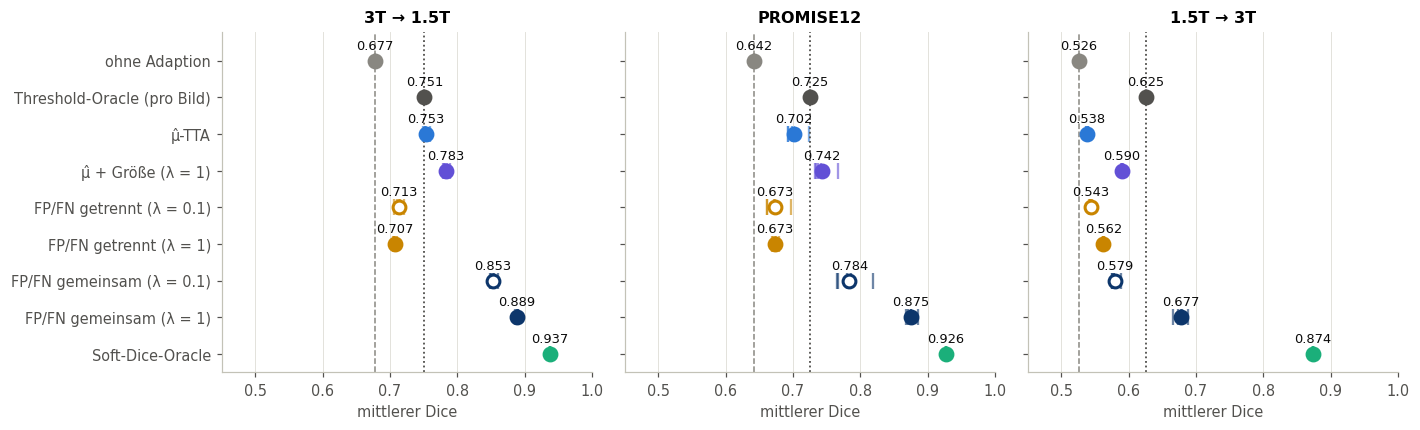

In [15]:
CMP8 = ["mu", "size1", "sep0.1", "sep1", "joint0.1", "joint1", "oracle"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0), sharey=True)
rows = ["Ausgang", "Threshold-Oracle"] + CMP8
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    r0 = R["mu", d, 0]
    base, thr = r0["dice_before"].mean(), r0["thr_oracle_dice"].mean()
    vals = {"Ausgang": [base], "Threshold-Oracle": [thr]}
    vals |= {v: per_pred(v, d, lambda r: r["dice_after"].mean()) for v in CMP8}
    ax.axvline(base, color=COL["Ausgang"], lw=1, ls="--")
    ax.axvline(thr, color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    for i, name in enumerate(rows):
        x = np.asarray(vals[name])
        ax.scatter(x, np.full(len(x), i), marker="|", s=120, color=COL[name], lw=1.5, alpha=0.6)
        hollow = name.endswith("0.1") and name in FPFN
        ax.scatter(x.mean(), i, s=70, edgecolor=COL[name], zorder=3, facecolor="white" if hollow else COL[name], lw=2)
        ax.text(x.mean(), i - 0.32, f"{x.mean():.3f}", ha="center", fontsize=8.5, color=INK)
    ax.set_title(dl); ax.set_xlim(0.45, 1.0); ax.set_xlabel("mittlerer Dice")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(rows)), [NAMES[r] for r in rows])
axes[0].set_ylim(len(rows) - 0.5, -0.8)
plt.tight_layout(); show(fig, "08_fpfn_ueberblick")

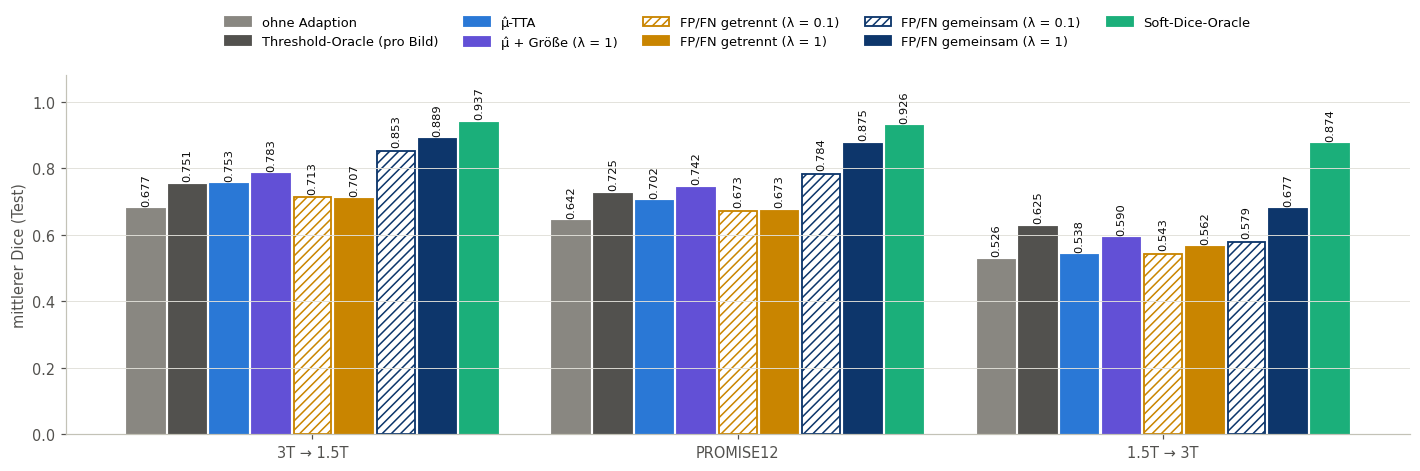

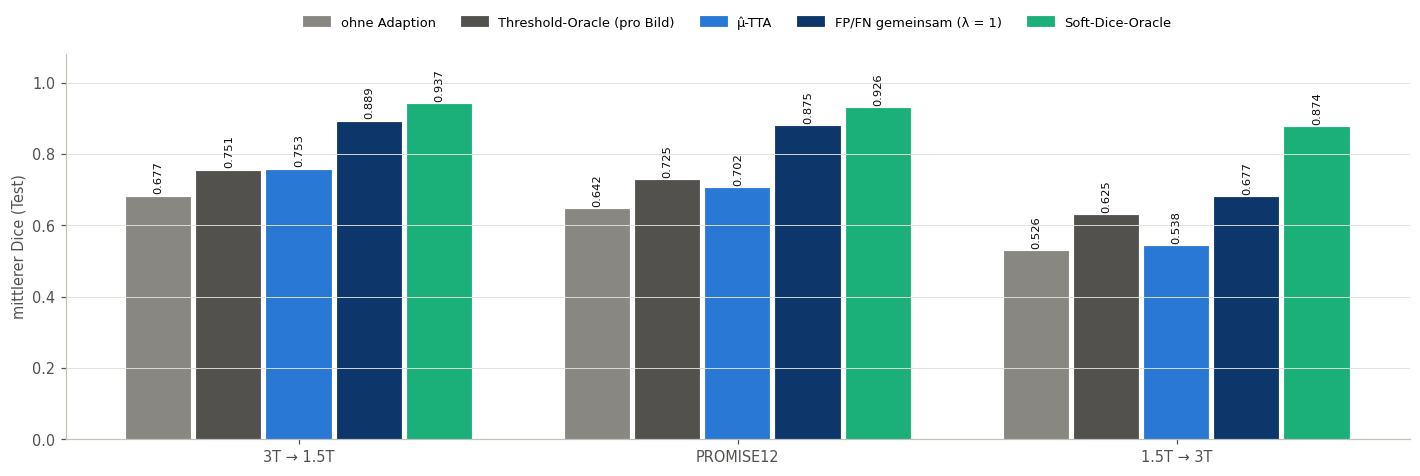

In [16]:
# same numbers as bars; λ = 0.1 hatched, λ = 1 filled
def bar_overview(keys, fname, w):
    bars = [("Ausgang", "ohne Adaption"), ("Threshold-Oracle", "Threshold-Oracle (pro Bild)")] + [(v, LABEL[v]) for v in keys]
    fig, ax = plt.subplots(figsize=(13, 4.4))
    for j, (key, label) in enumerate(bars):
        light = key in FPFN and key.endswith("0.1")
        for i, d in enumerate(DOMAINS):
            r0 = R["mu", d, 0]
            if key == "Ausgang":
                m = r0["dice_before"].mean()
            elif key == "Threshold-Oracle":
                m = r0["thr_oracle_dice"].mean()
            else:
                m = per_pred(key, d, lambda r: r["dice_after"].mean()).mean()
            xpos = i + (j - (len(bars) - 1) / 2) * w
            ax.bar(xpos, m, width=w * 0.9, facecolor="white" if light else COL[key], edgecolor=COL[key], lw=1.2,
                   hatch="////" if light else None, label=label if i == 0 else None)
            ax.text(xpos, m + 0.01, f"{m:.3f}", ha="center", fontsize=7.5, rotation=90, va="bottom", color=INK)
    ax.set_xticks(range(len(DOMAINS)), DOMAINS.values()); ax.set_ylim(0, 1.08)
    ax.set_ylabel("mittlerer Dice (Test)"); ax.grid(axis="x", visible=False)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.2 if len(bars) > 5 else 1.13), fontsize=8.5)
    plt.tight_layout(); show(fig, fname)


bar_overview(CMP8, "08a_fpfn_ueberblick_balken", w=0.098)
# reduced: only the FP/FN oracle that works (joint, λ = 1) against μ̂-TTA and the references
bar_overview(["mu", "joint1", "oracle"], "08a_fpfn_ueberblick_balken_kurz", w=0.16)

Die Zahlen dazu (Schwelle für verbessert / geschädigt ±0.05) und welcher Anteil des Abstands
μ̂-TTA → Soft-Dice-Oracle geschlossen wird.

**Einordnung:**
- Die gemeinsame Form ist über die Predictoren sehr stabil (Std ≤ 0.007 bei λ = 1) und ist pro Fall
  in 94 / 94 / 80 % besser als die μ̂-TTA, in höchstens 2 % schlechter.
- Mit λ = 1 *unterschätzt* μ̂ am Ende auf 3T → 1.5T und PROMISE12 (−0.08 / −0.07): Der Dice steigt
  über das hinaus, was μ̂ für möglich hält. Der FP/FN-Term treibt die Adaption, μ̂ spielt kaum noch eine
  Rolle. Auf 1.5T → 3T überschätzt μ̂ weiter (+0.18).
- λ = 0.1 ist für die gemeinsame Form zu schwach, vor allem auf 1.5T → 3T (0.579, kaum über der
  Größe mit 0.590). Dort setzt sich der μ̂-Term gegen den FP/FN-Term durch.

In [17]:
CMP8T = ["mu", "size1", "sep0.1", "sep1", "joint0.1", "joint1", "oracle"]
tab8 = pd.DataFrame({(DOMAINS[d], LABEL[v]): summary(v, d) for d in DOMAINS for v in CMP8T}).T
tab8.index.names = ["Domäne", "Konfiguration"]
display(tab8.style.format({"Dice nachher": "{:.3f}", "Δ Dice": "{:+.3f}", "Std über Predictoren": "{:.3f}",
                           "verbessert": "{:.1%}", "geschädigt": "{:.1%}", "μ̂ − Dice nachher": "{:+.3f}"}))
gap8 = {DOMAINS[d]: {LABEL[v]: (tab8.loc[(DOMAINS[d], LABEL[v]), "Dice nachher"] - tab8.loc[(DOMAINS[d], LABEL["mu"]), "Dice nachher"])
                     / (tab8.loc[(DOMAINS[d], LABEL["oracle"]), "Dice nachher"] - tab8.loc[(DOMAINS[d], LABEL["mu"]), "Dice nachher"])
                     for v in ["size1", "joint0.1", "joint1"]} for d in DOMAINS}
print("Anteil der Lücke μ̂-TTA → Soft-Dice-Oracle, der geschlossen wird:")
display(pd.DataFrame(gap8).T.style.format("{:.0%}"))

Anteil der Lücke μ̂-TTA → Soft-Dice-Oracle, der geschlossen wird:


,μ̂ + Größe (λ = 1),FP/FN gemeinsam (λ = 0.1),FP/FN gemeinsam (λ = 1)
3T → 1.5T,16%,54%,73%
PROMISE12,18%,36%,77%
1.5T → 3T,15%,12%,41%


Mittlere FP und FN pro Bild vor und nach der Adaption (λ = 1), zum Vergleich die Größe (O3).

**Einordnung:** Getrennt tauscht FN gegen FP: Auf 1.5T → 3T fallen die FP von 1621 auf 218, die FN
steigen von 2069 auf 2438. Gemeinsam senkt beide: 3T → 1.5T FP 653 → 140, FN 1590 → 430. Die
Größe (O3) gleicht dagegen nur FP und FN aneinander an (FP steigt sogar), die Summe der Fehlerpixel
sinkt viel weniger.

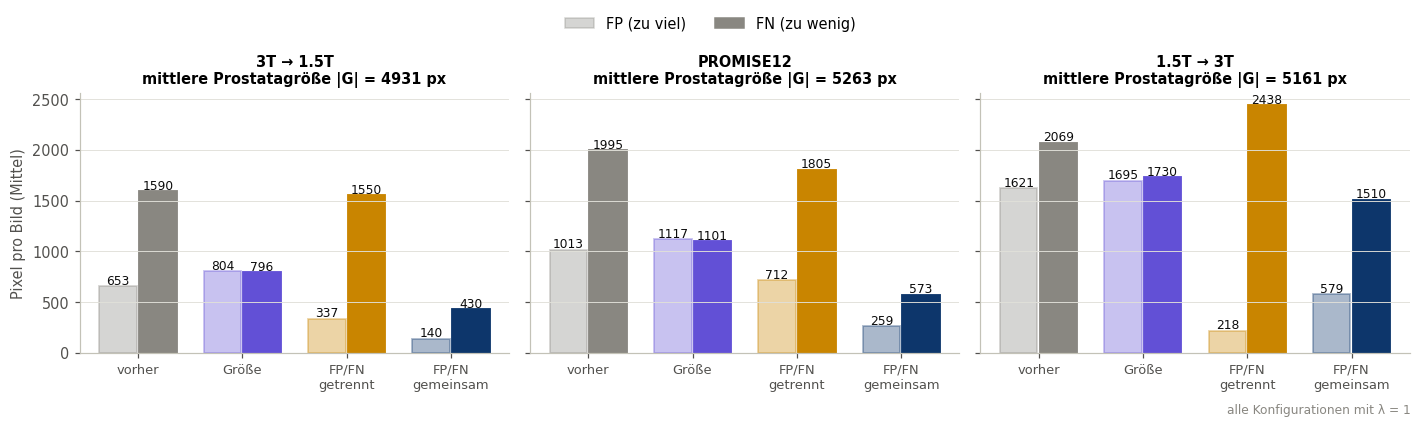

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
groups8 = [("vorher", None), ("Größe", "size1"), ("FP/FN\ngetrennt", "sep1"), ("FP/FN\ngemeinsam", "joint1")]
w = 0.36
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for i, (gl, v) in enumerate(groups8):
        src = v or "joint1"
        fp = pooled(src, d, "fp_before" if v is None else "fp_after").mean()
        fn = pooled(src, d, "fn_before" if v is None else "fn_after").mean()
        c = COL["Ausgang"] if v is None else COL[v]
        ax.bar(i - w / 2 - 0.01, fp, width=w, color=c, alpha=0.35, edgecolor=c, lw=1.2)
        ax.bar(i + w / 2 + 0.01, fn, width=w, color=c, edgecolor=c, lw=1.2)
        ax.text(i - w / 2 - 0.01, fp + 20, f"{fp:.0f}", ha="center", fontsize=8, color=INK)
        ax.text(i + w / 2 + 0.01, fn + 20, f"{fn:.0f}", ha="center", fontsize=8, color=INK)
    g = pooled("joint1", d, "size_gt").mean()
    ax.set_title(f"{dl}\nmittlere Prostatagröße |G| = {g:.0f} px", fontsize=9.5)
    ax.set_xticks(range(len(groups8)), [gl for gl, _ in groups8], fontsize=8.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Pixel pro Bild (Mittel)")
fig.legend(handles=[Patch(facecolor=MUTED, alpha=0.35, edgecolor=MUTED, label="FP (zu viel)"),
                    Patch(facecolor=MUTED, edgecolor=MUTED, label="FN (zu wenig)")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.text(0.99, 0.005, "alle Konfigurationen mit λ = 1", ha="right", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.02, 1, 0.95)); show(fig, "08b_fpfn_fp_fn")

Verlauf über die Schritte. Oben der mittlere echte Dice, darunter der Median der weichen FP und FN
(die Größen, die in der Strafe stehen) für die beiden FP/FN-Formen.

**Einordnung:**
- **Getrennt:** Die FP fallen in den ersten ~25 Schritten fast auf 0 (Median 260 → 4 auf
  3T → 1.5T), gleichzeitig steigen die FN. Der Dice steigt kurz und fällt bis Schritt ~45 unter den
  Ausgangswert; erst wenn FP ≈ 0 ist, sinken die FN wieder etwas. Am Ende liegt er klar unter der
  μ̂-TTA. Das ist das Produkt-Minimum: Ist FP erst klein, bringt jedes weitere
  entfernte FP-Pixel viel mehr als ein gewonnenes FN-Pixel kostet, weil die Ableitung von log(1 + FP)
  gleich 1 / (1 + FP) ist.
- **Gemeinsam:** Zuerst fallen vor allem die FN (die Masken sind anfangs zu klein; auf 3T → 1.5T
  bleiben die FP die ersten ~30 Schritte fast gleich), dann auch die FP.
  Der Dice steigt nach 100 Schritten noch an, auf allen drei Shifts. Mit mehr Schritten wäre noch
  etwas mehr drin, das Soft-Dice-Oracle steigt aber genauso weiter.

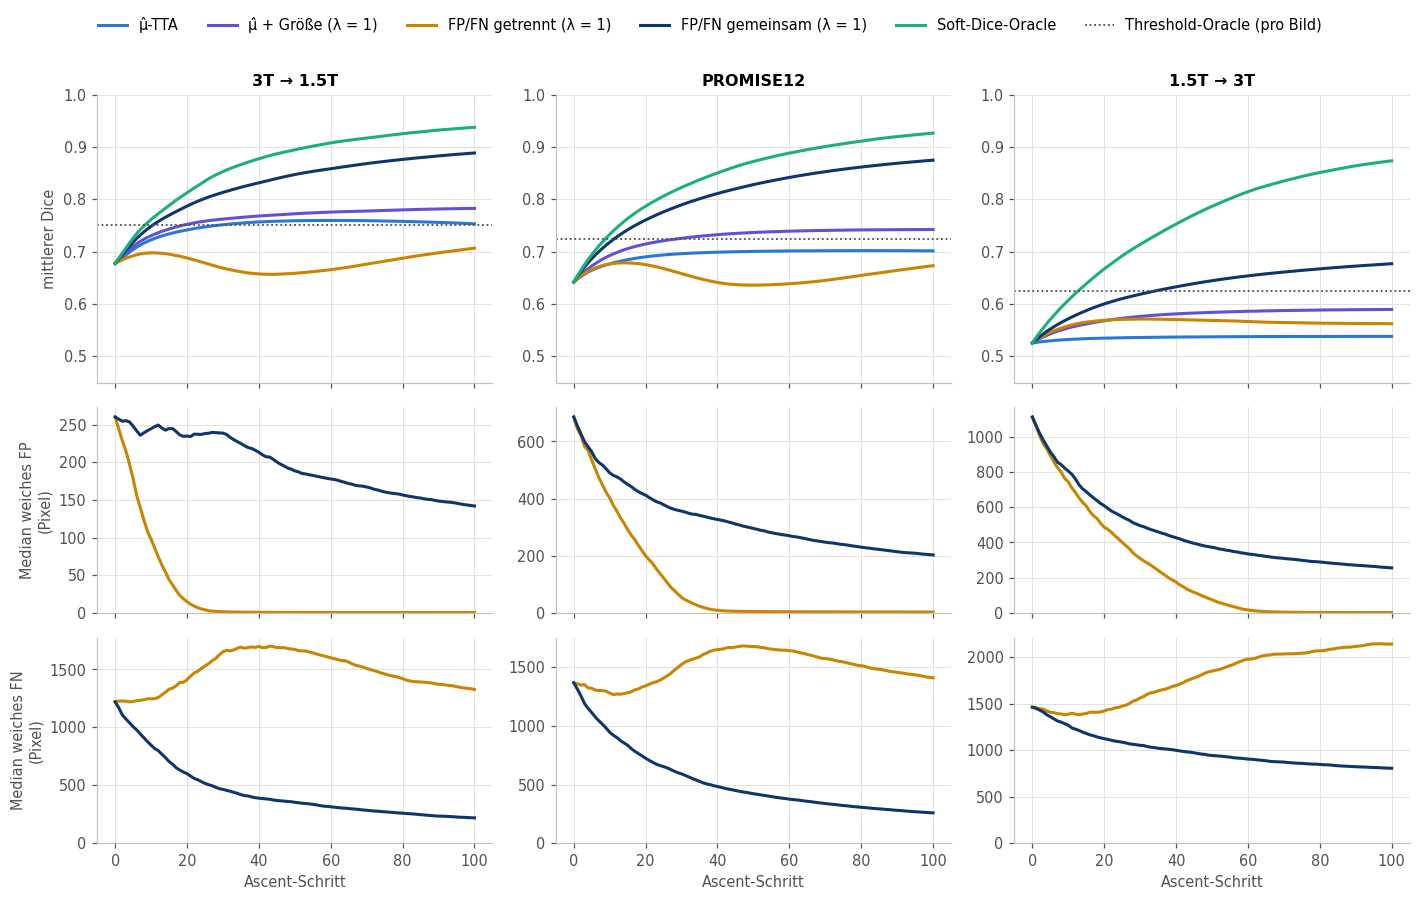

In [19]:
TRJ = ["mu", "size1", "sep1", "joint1", "oracle"]
fig, axes = plt.subplots(3, 3, figsize=(13, 8.2), sharex=True, gridspec_kw={"height_ratios": [1.4, 1, 1]})
for k, (d, dl) in enumerate(DOMAINS.items()):
    ax = axes[0, k]
    for v in TRJ:
        ax.plot(pooled(v, d, "dice_per_step").mean(0), color=COL[v])
    ax.axhline(R["mu", d, 0]["thr_oracle_dice"].mean(), color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS)
    ax.set_title(dl); ax.set_ylim(0.45, 1.0)
    for row, key in ((1, "fp_soft_per_step"), (2, "fn_soft_per_step")):
        for v in ["sep1", "joint1"]:
            axes[row, k].plot(np.median(pooled(v, d, key), 0), color=COL[v])
        axes[row, k].set_ylim(0, None)
    axes[2, k].set_xlabel("Ascent-Schritt")
axes[0, 0].set_ylabel("mittlerer Dice")
axes[1, 0].set_ylabel("Median weiches FP\n(Pixel)"); axes[2, 0].set_ylabel("Median weiches FN\n(Pixel)")
handles = [Line2D([], [], color=COL[v], label=LABEL[v]) for v in TRJ]
handles += [Line2D([], [], color=COL["Threshold-Oracle"], lw=1.2, ls=THR_LS, label="Threshold-Oracle (pro Bild)")]
plt.tight_layout(rect=(0, 0, 1, 0.94))
fig.legend(handles=handles, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.0))
show(fig, "08c_fpfn_verlauf")

Anteil der Fälle, die besser, gleich oder schlechter werden (±0.05 Dice):

**Einordnung:** Die gemeinsame Form mit λ = 1 verbessert 86 / 91 / 65 % der Fälle und schadet
höchstens 0.3 %. Die getrennte Form schadet in jedem vierten Fall.

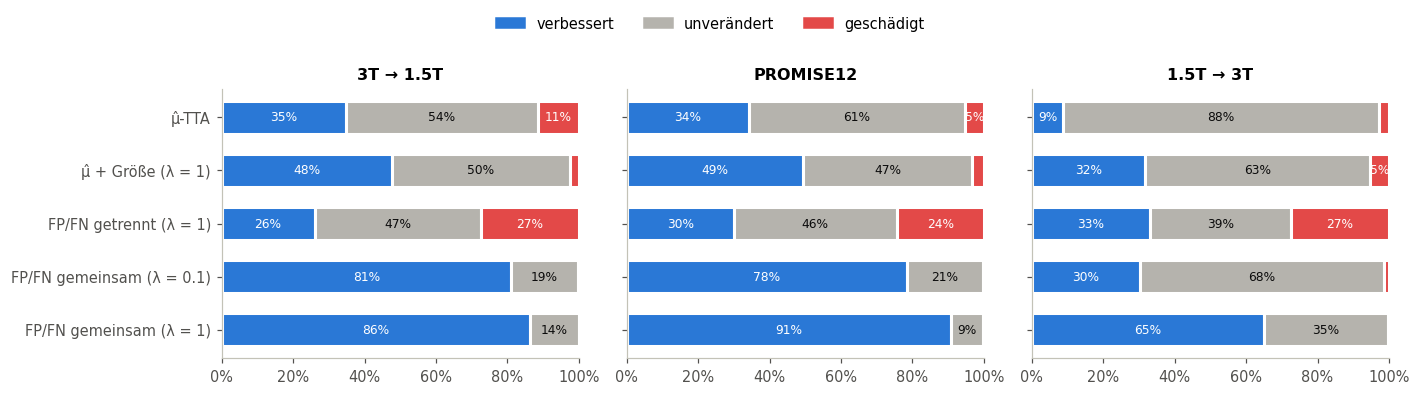

In [20]:
CMPG = ["mu", "size1", "sep1", "joint0.1", "joint1"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (d, dl) in zip(axes, DOMAINS.items()):
    for i, v in enumerate(CMPG):
        dd = pooled(v, d, "dice_after") - pooled(v, d, "dice_before")
        parts = {"verbessert": (dd > TOL).mean(), "unverändert": (np.abs(dd) <= TOL).mean(), "geschädigt": (dd < -TOL).mean()}
        left = 0
        for kk, x in parts.items():
            ax.barh(i, x, left=left, color=GROUP_COL[kk], height=0.62, edgecolor="white", lw=2)
            if x > 0.04:
                ax.text(left + x / 2, i, f"{x:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if kk != "unverändert" else INK)
            left += x
    ax.set_title(dl); ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1); ax.grid(visible=False)
axes[0].set_yticks(range(len(CMPG)), [LABEL[v] for v in CMPG]); axes[0].invert_yaxis()
fig.legend(handles=[Patch(color=c, label=k) for k, c in GROUP_COL.items()], loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(rect=(0, 0, 1, 0.93)); show(fig, "08d_fpfn_verbessert_geschaedigt")

Beispiele wie in Abschnitt 7, Predictor 0, ausgewählt aus allen Testfällen für die gemeinsame Form
(λ = 1):
- **gut:** die 2 Fälle mit dem größten Gewinn gegenüber der μ̂-TTA,
- **schlechter als μ̂-TTA:** die 2 Fälle mit dem größten Verlust gegenüber der μ̂-TTA,
- **schwächste:** die 2 Fälle (ohne die vorigen) mit dem kleinsten Gewinn gegenüber ohne Adaption.
  Geschädigt wird mit dieser Form fast kein Fall, deshalb „schwächste“ statt „schadet“.

Spalten: ohne Adaption, μ̂-TTA, getrennte Form, gemeinsame Form (beide λ = 1), Soft-Dice-Oracle.
Grün: richtig, rot: zu viel (FP), blau: fehlt (FN); Zahl im Titel: Dice.

**Aussage:**
- **Gut:** Fast alle guten Fälle haben dasselbe Ausgangsbild: Die Prostata ist komplett FN (Dice
  ≈ 0), daneben eine falsche Region (FP). Die μ̂-TTA ändert daran nichts. Die gemeinsame Form
  löscht die falsche Region *und* lässt die Maske an der richtigen Stelle wachsen (0.93–0.97), oft
  so gut wie das Soft-Dice-Oracle (3T → 1.5T Fall 200 sogar besser: 0.96 vs. 0.79). Die getrennte
  Form schafft das nur teilweise (0.61–0.79) oder gar nicht.
- **Fehlschläge:** Das Muster ist umgekehrt wie bei der Größe in Abschnitt 7. Dort wurde die falsche
  Region *vergrößert*; hier landet die Adaption bei einer **leeren oder fast leeren Maske**:
  - Die Prostata ist anfangs komplett FN (3T → 1.5T Fall 393, 179, 249, 43; 1.5T → 3T Fall 128, 582):
    Die falsche Region verschwindet, an der Prostata entsteht aber nichts. Dice 0, obwohl die μ̂-TTA
    in Fall 393 und 179 einen Teil gefunden hatte (0.36 / 0.13).
  - Die Maske trifft teilweise, hat aber viel FP (PROMISE12 Fall 501, 599, 385): Die Adaption
    schrumpft die ganze Maske und verliert dabei auch die richtigen Pixel (0.29 / 0.04 / 0.00).

  Löschen ist offenbar die „billige“ Richtung: FP lassen sich überall gleichzeitig senken, während
  an der Prostata erst Wahrscheinlichkeiten nahe 0 angehoben werden müssen. Eine leere Maske ist
  dann ein lokales Minimum mit FP = 0 und FN = |G|. Das Soft-Dice-Oracle findet in all diesen Fällen
  die Prostata (0.46–0.95). Woran der Unterschied genau liegt (Gewichtung von FN gegenüber FP oder
  der μ̂-Term, der bei der FP/FN-Strafe noch mitläuft), haben wir noch nicht getrennt.
- **Reproduzierbarkeit:** Wie in Abschnitt 7 weichen einzelne Fälle beim Nachrechnen ab, jetzt auch
  mit der gemeinsamen Form (PROMISE12 Fall 599: 0.04 statt 0.12; 1.5T → 3T Fall 385: 0.00 statt
  0.21). Ursache ist auch hier der μ̂-Term im Objective: Das Soft-Dice-Oracle bleibt reproduzierbar.

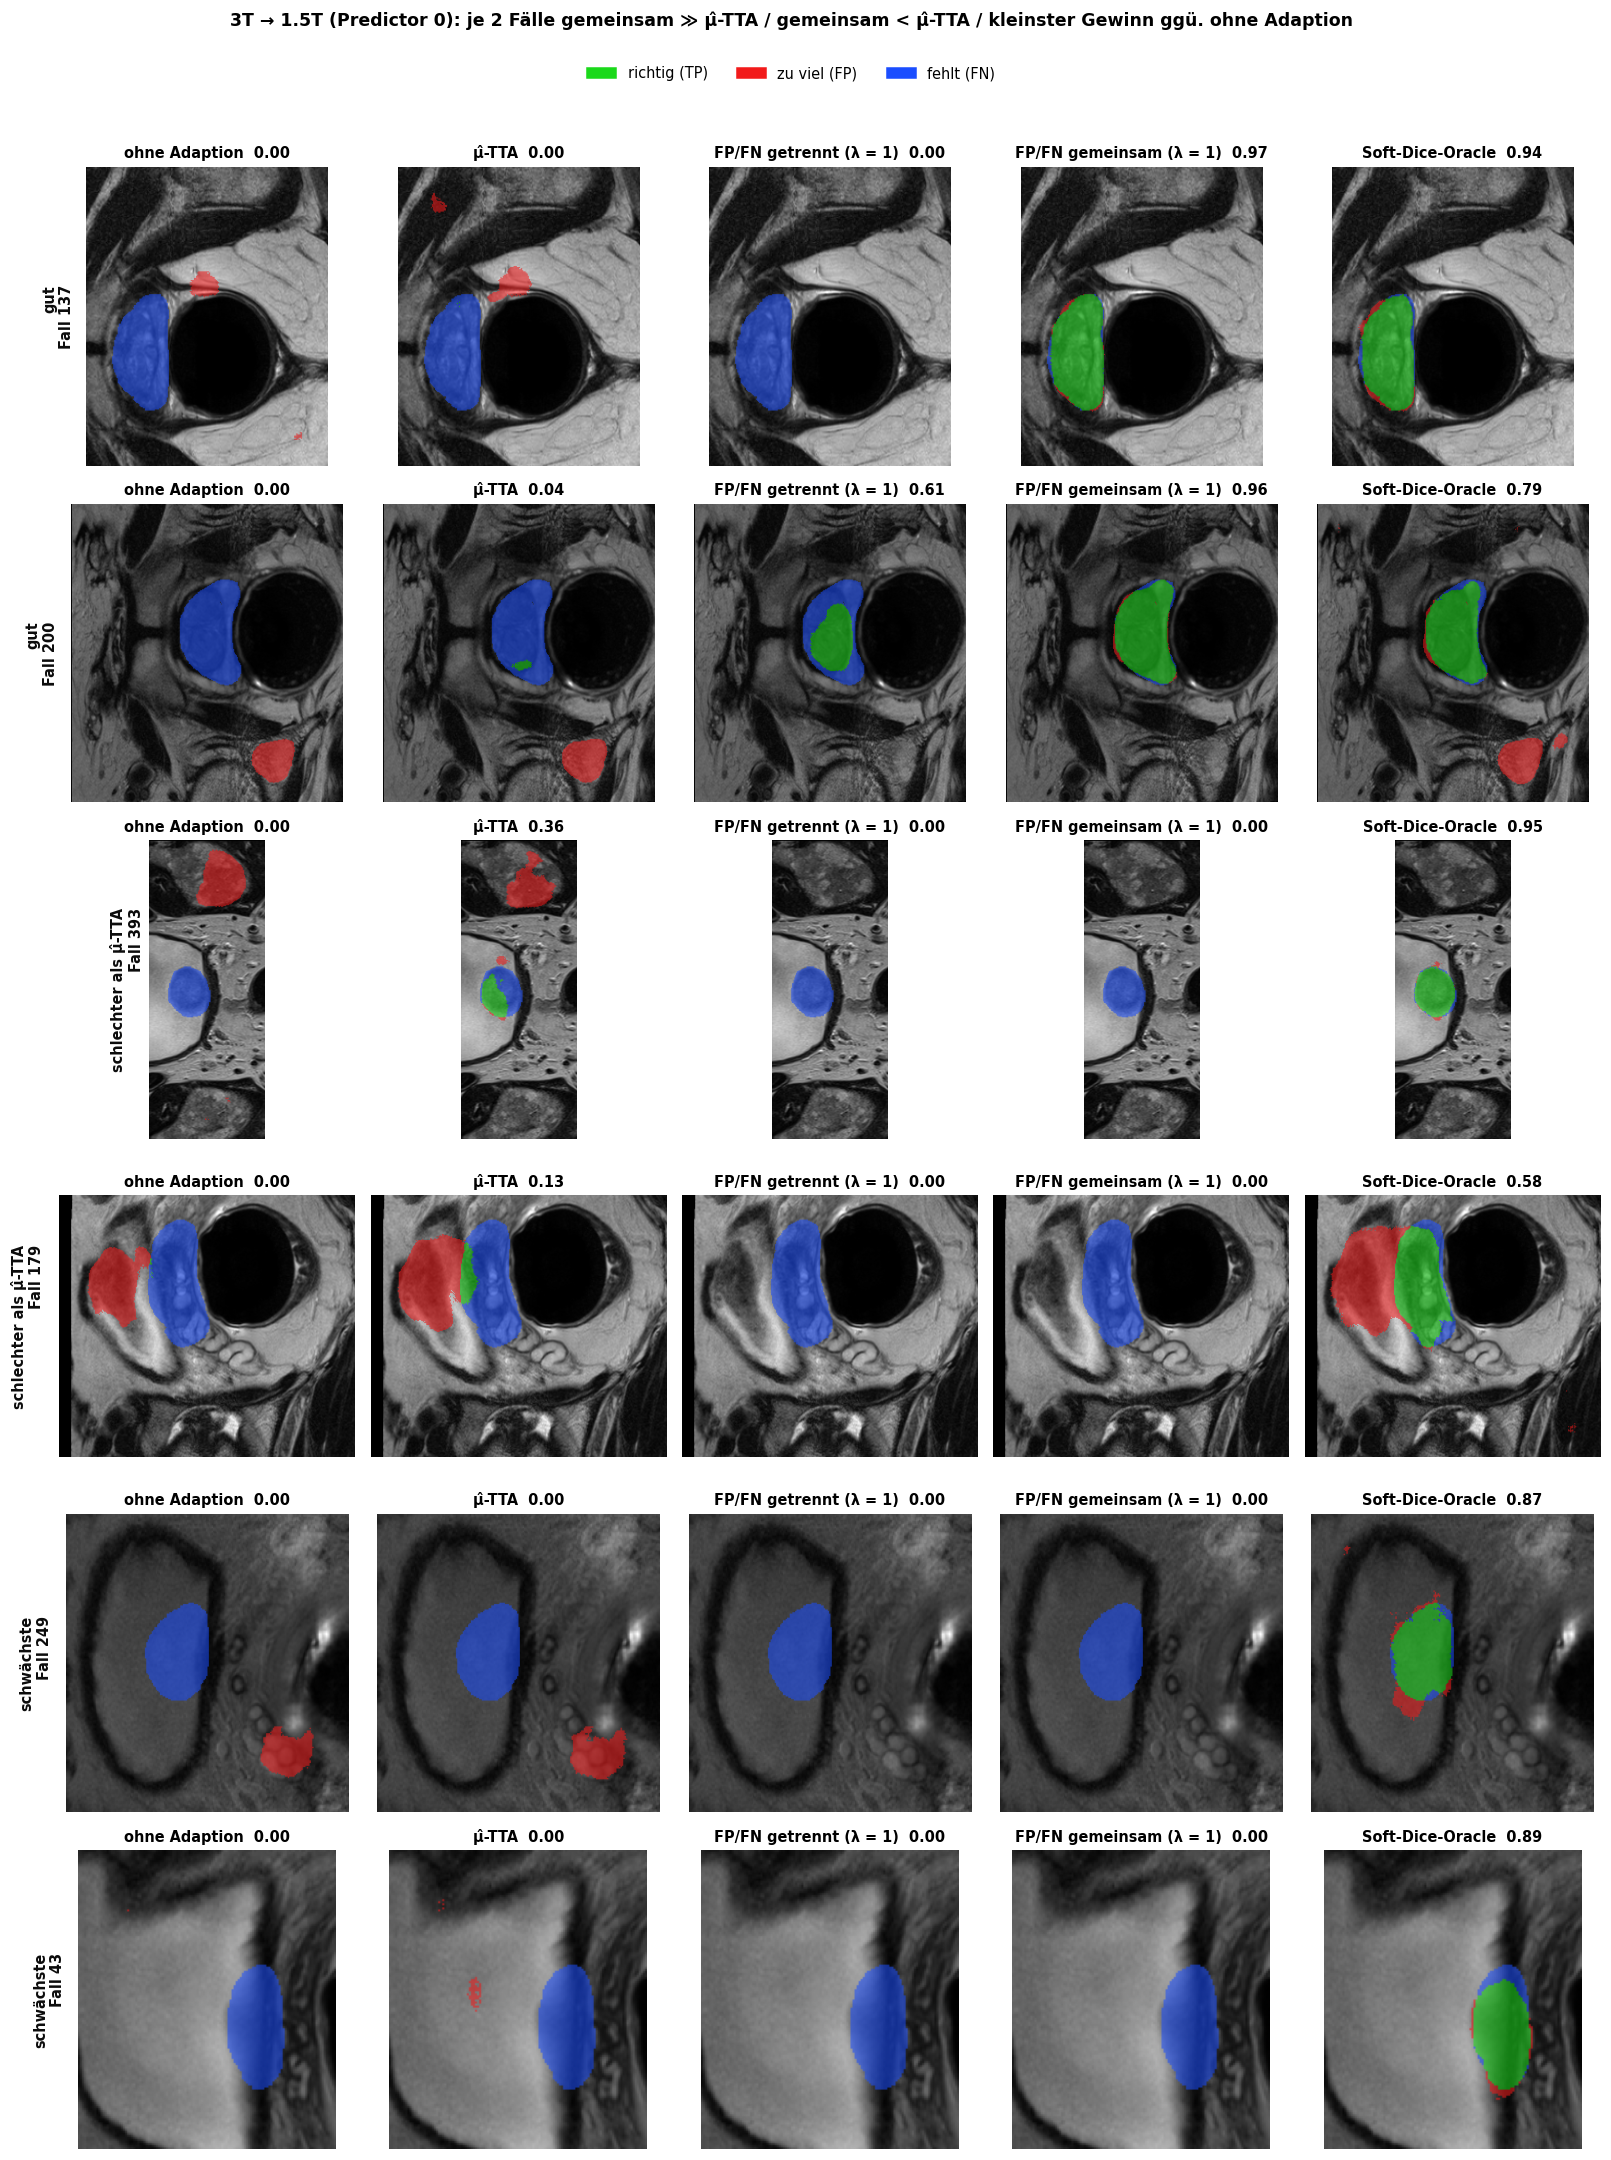

3T → 1.5T: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei keinem Fall


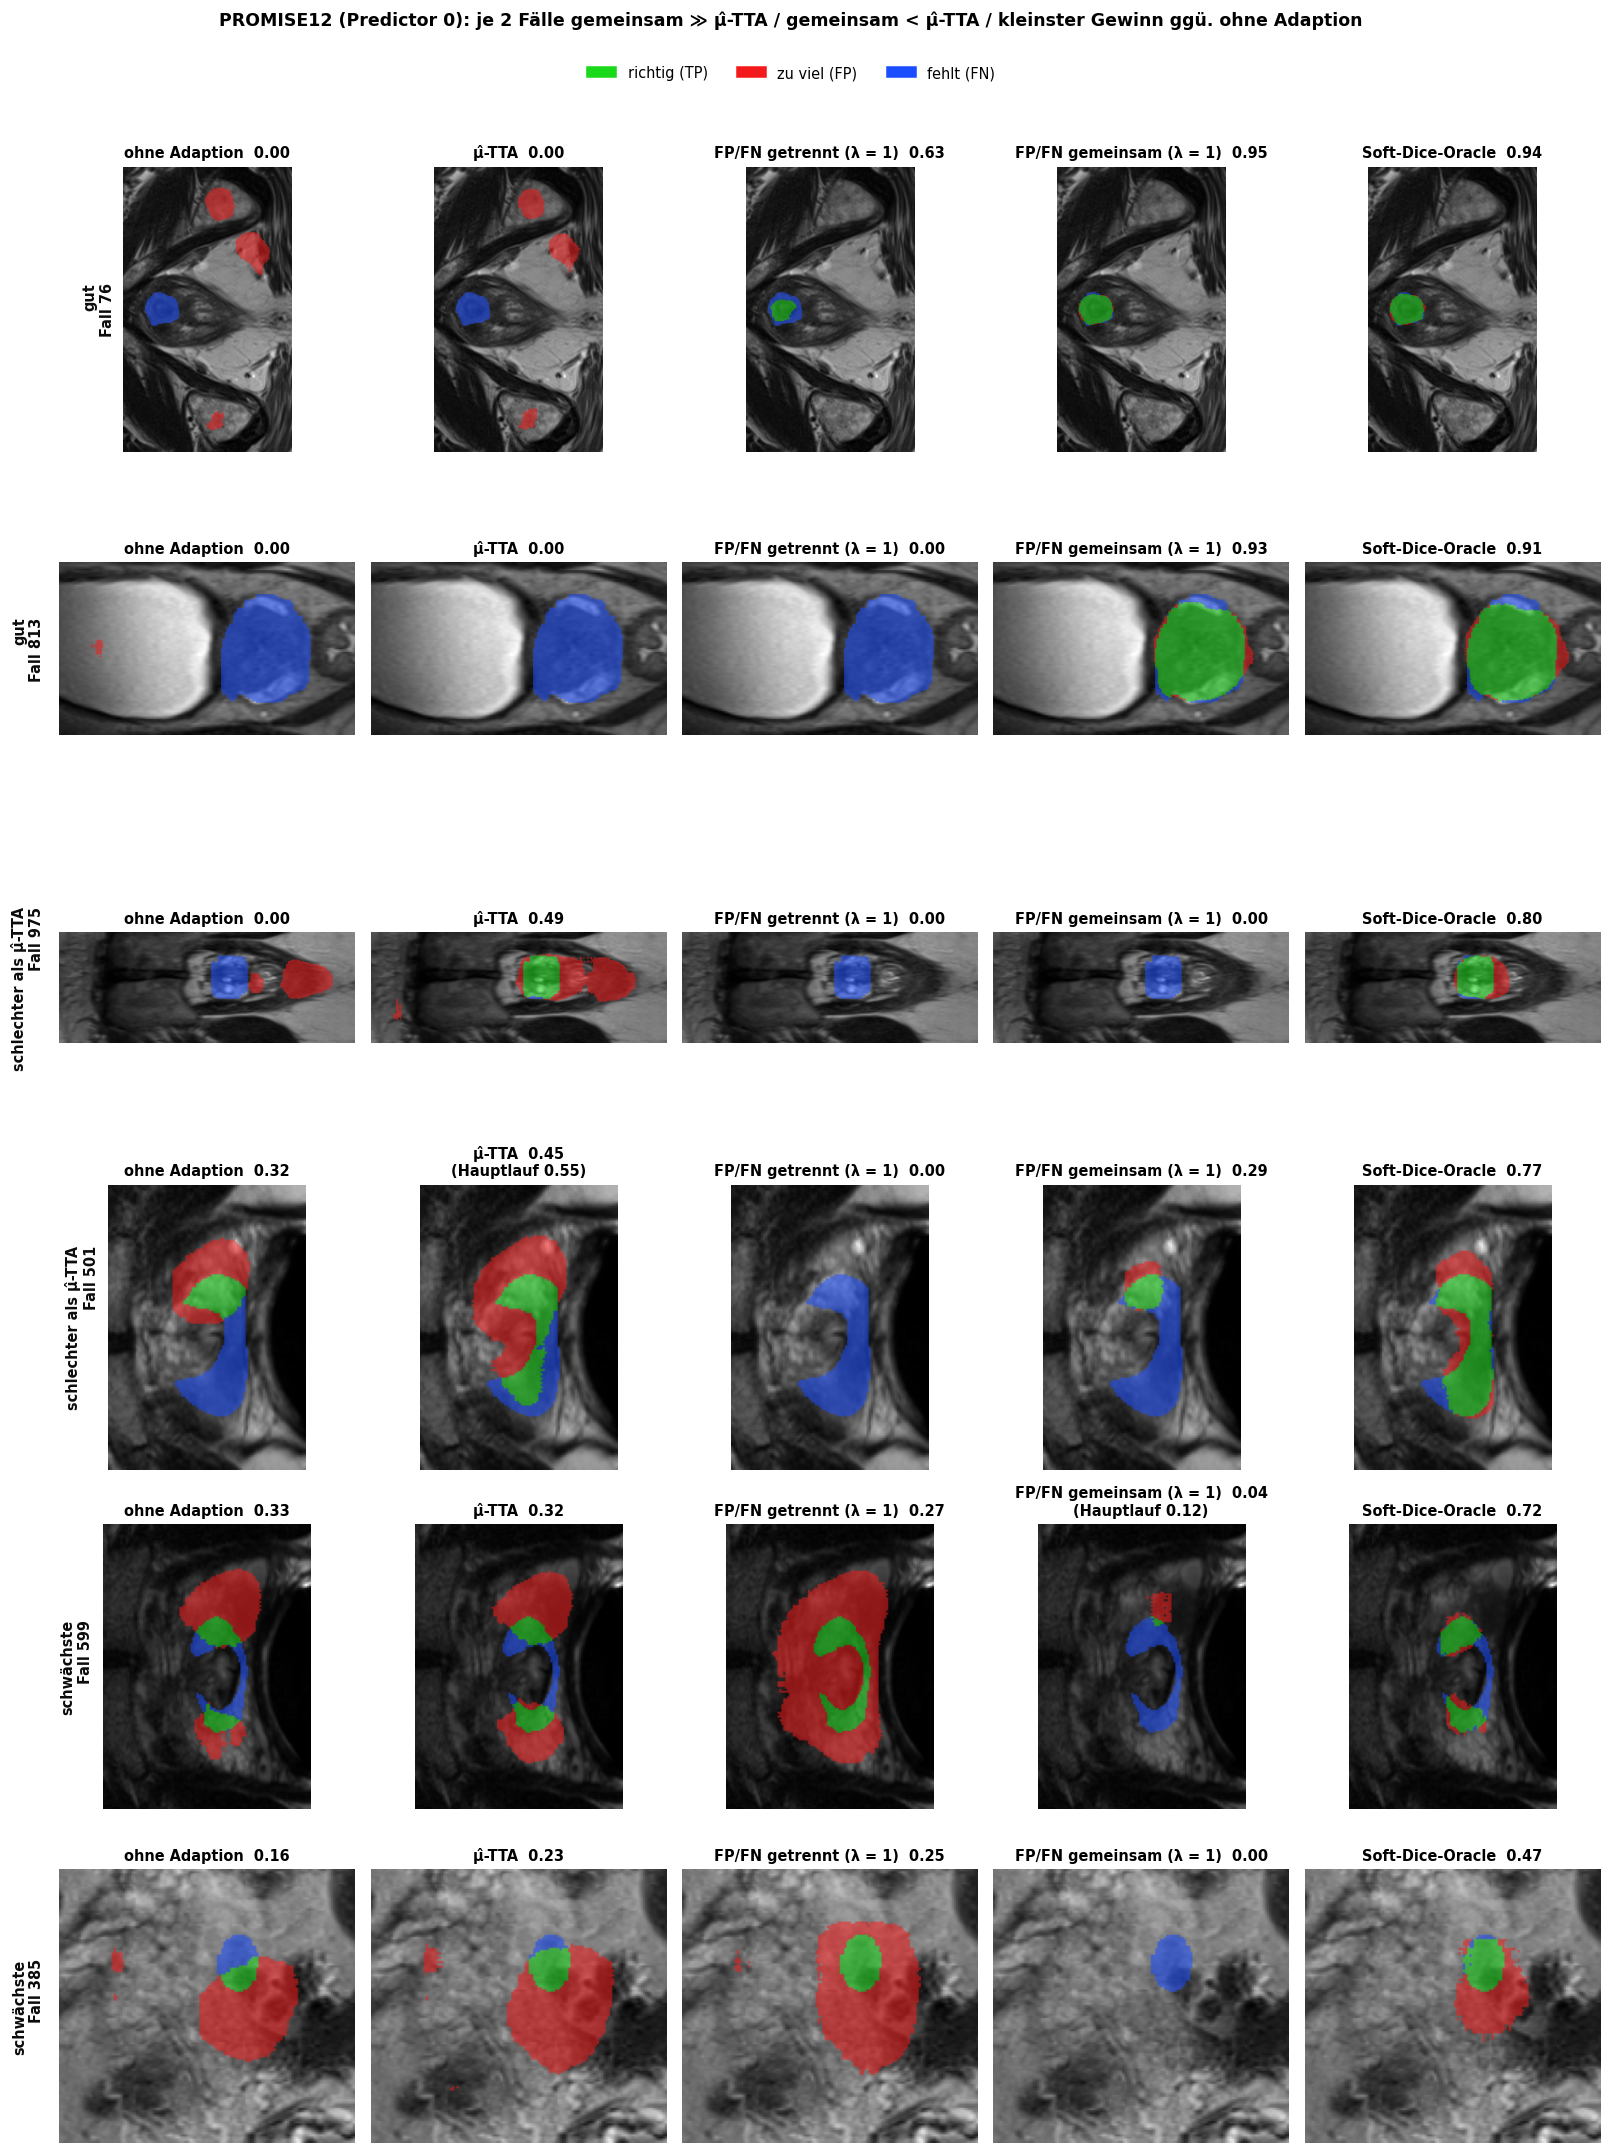

PROMISE12: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei Fall 501 μ̂-TTA (0.45 statt 0.55), Fall 599 FP/FN gemeinsam (λ = 1) (0.04 statt 0.12)


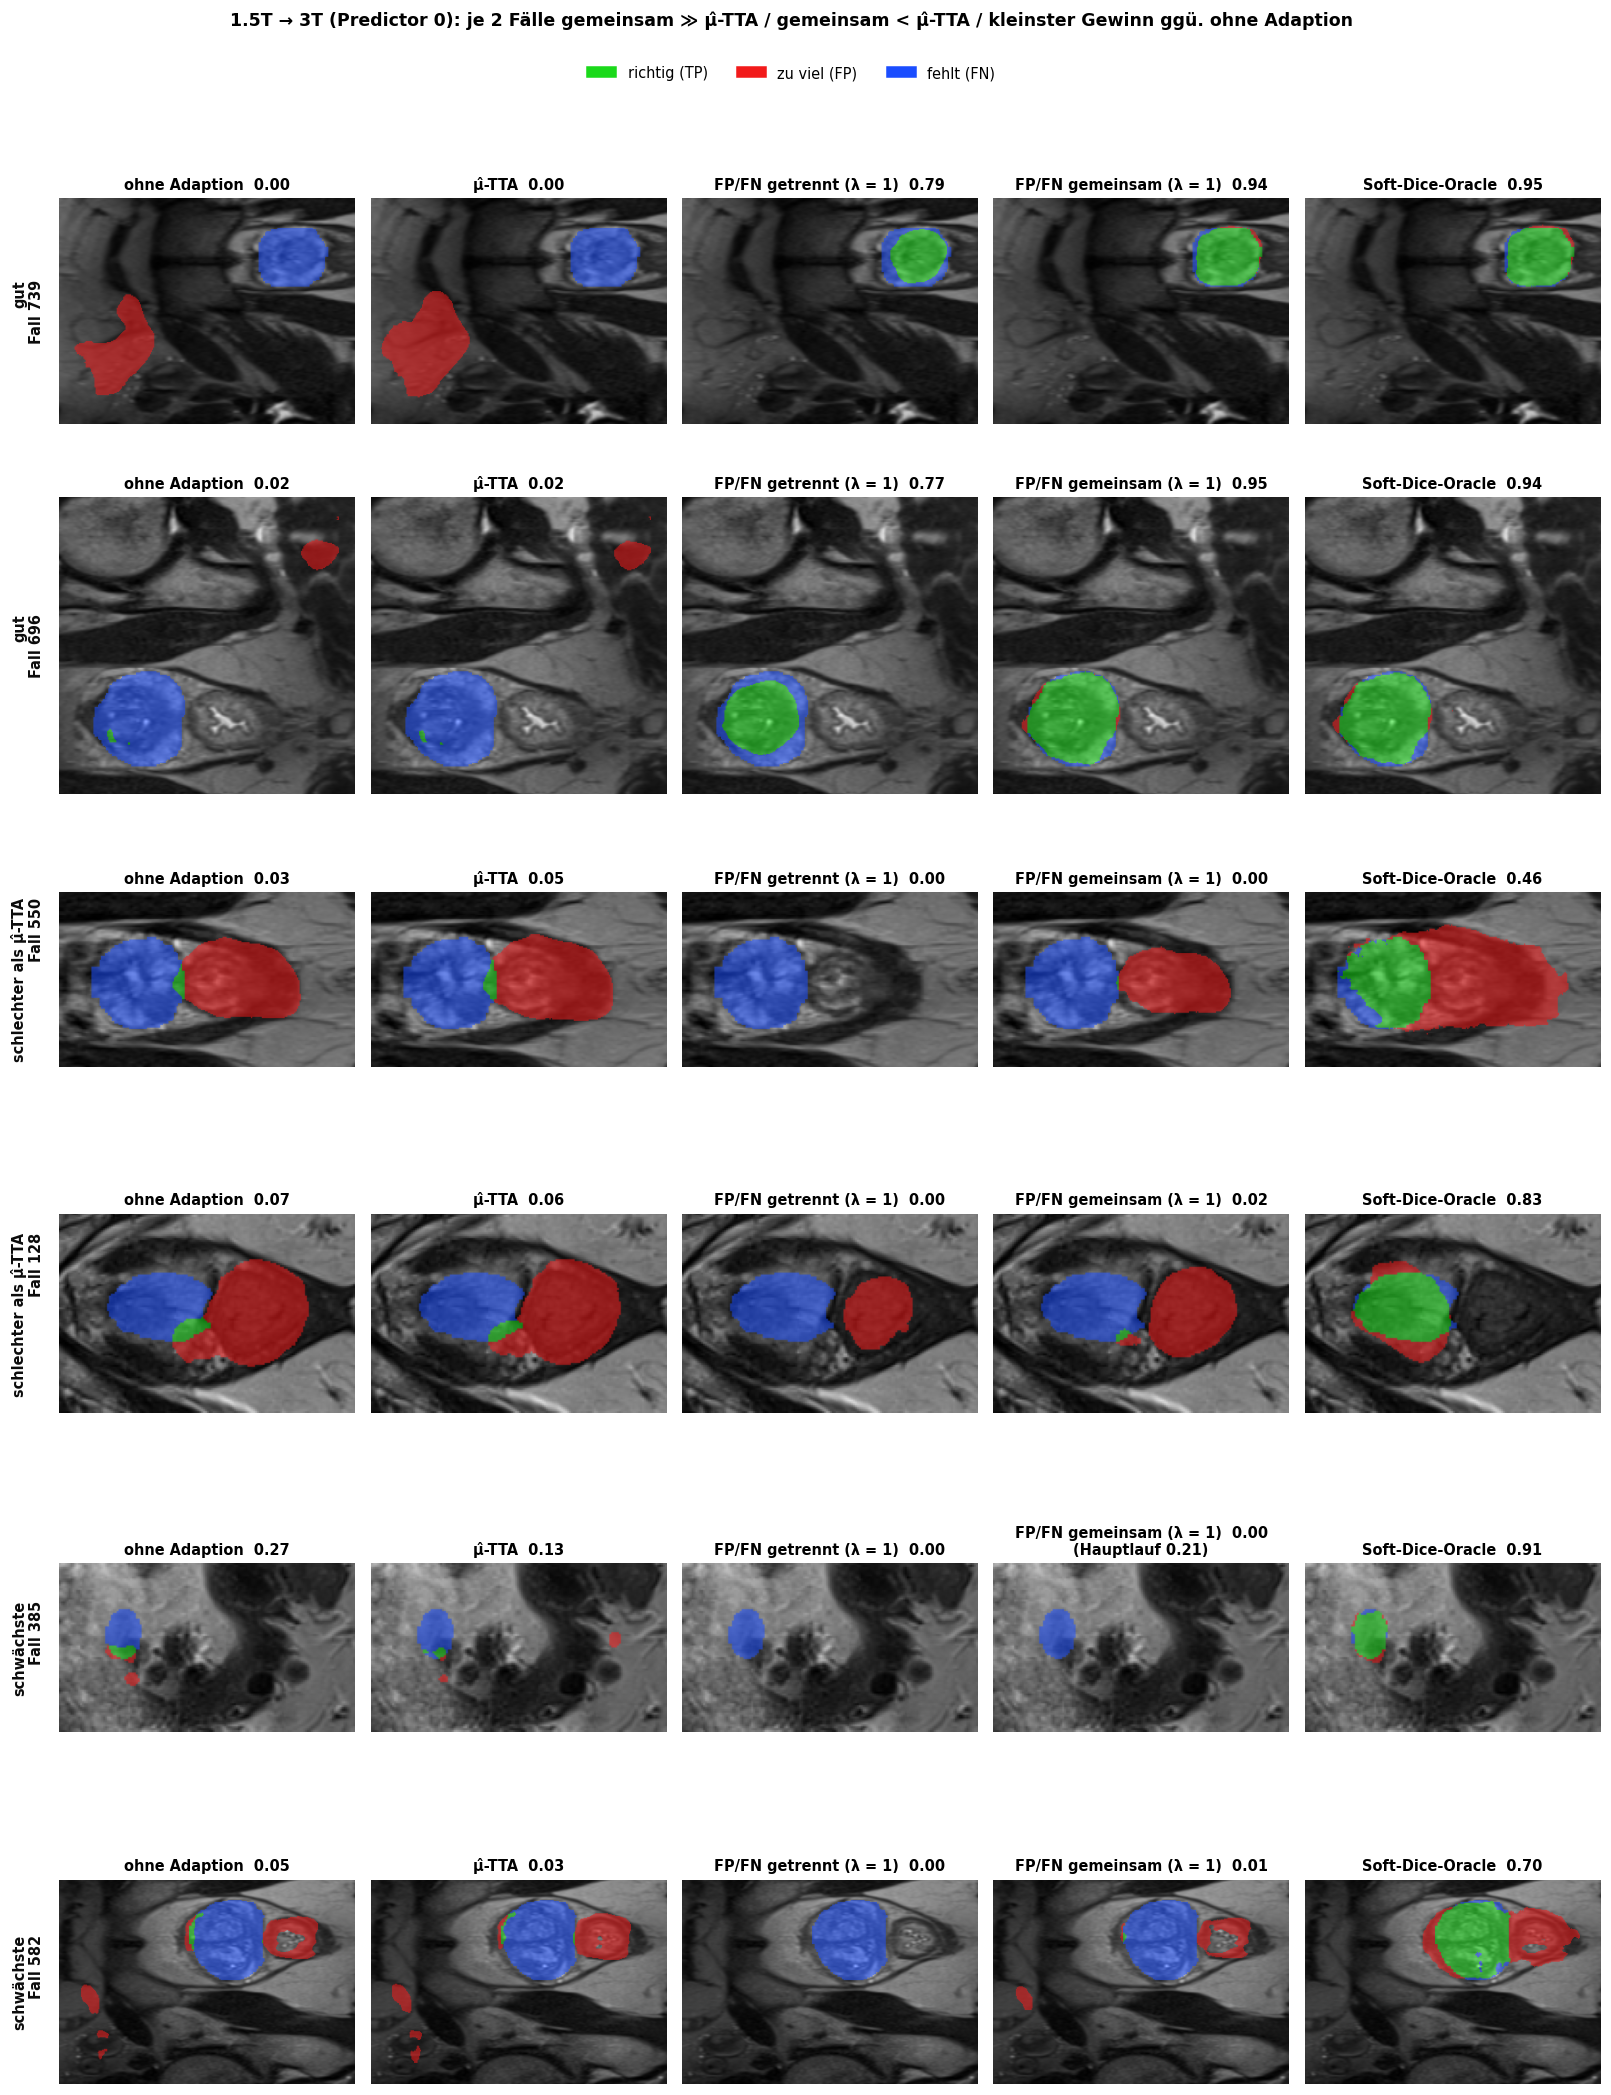

1.5T → 3T: Re-Run weicht um > 0.05 Dice vom Hauptlauf ab bei Fall 385 FP/FN gemeinsam (λ = 1) (0.00 statt 0.21)


In [21]:
# same procedure as in section 7, cases chosen for FP/FN joint (λ = 1) vs. μ̂-TTA
SHOW8 = ["mu", "sep1", "joint1", "oracle"]
EX_RUNS8 = {"mu": "latent_tta_examples_fpfn_mu", "sep1": "latent_tta_examples_fpfn_sep_w1.0",
            "joint1": "latent_tta_examples_fpfn_joint_w1.0", "oracle": "latent_tta_examples_fpfn_oracle"}
NAMES8 = ["ohne Adaption", "μ̂-TTA", "FP/FN getrennt (λ = 1)", "FP/FN gemeinsam (λ = 1)", "Soft-Dice-Oracle"]
GROUPS8 = [("gut", "gemeinsam ≫ μ̂-TTA"), ("schlechter als μ̂-TTA", "gemeinsam < μ̂-TTA"),
           ("schwächste", "kleinster Gewinn ggü. ohne Adaption")]


def select_cases8(d, k=2):
    dm, dj = R["mu", d, 0]["dice_after"], R["joint1", d, 0]["dice_after"]
    d0 = R["mu", d, 0]["dice_before"]
    good = list(np.argsort(-(dj - dm))[:k])
    worse = list(np.argsort(dj - dm)[:k])
    weak = [i for i in np.argsort(dj - d0) if i not in good + worse][:k]
    return [int(i) for i in good + worse + weak]


for d in DOMAINS:
    example_panel(d, show_v=SHOW8, ex_runs=EX_RUNS8, names=NAMES8, select=select_cases8, groups=GROUPS8,
                  fname="08e_fpfn_beispiele")

## 9 · Fazit und nächste Schritte

**Fazit**
1. **Das Signal lohnt sich.** Mit perfekter Größe (O3) verbessert sich der Dice gegenüber der μ̂-TTA
   um +0.03 / +0.04 / +0.05, konsistent für alle 5 Predictoren und mit weniger geschädigten Fällen
   auf 3T → 1.5T und PROMISE12.
2. **Es ist robust.** ±30 % Rauschen auf FP₀ und FN₀ kostet ≤ 0.003 Dice. Ein Head muss FP und FN
   also nicht exakt treffen; die Zielgröße sollte aber ungefähr innerhalb von ±8 % liegen.
3. **Es reicht nicht bis zum Soft-Dice-Oracle.** Danach ist FP ≈ FN, der Rest ist ein Lagefehler. Zwei
   Zahlen FP und FN enthalten keine Information über die Lage, nur über die Größe. Das ist kein
   Problem des Oracles, sondern eine Grenze des Signals.
   Wenn die Maske aus einer richtigen und einer falschen Region besteht, kann der Größenterm sogar
   die richtige Region löschen; das ist das Muster aller Fehlschläge in Abschnitt 7.
4. **μ̂ überschätzt weiter**, auf 1.5T → 3T um +0.27. Der Größenterm bremst die Adaption, korrigiert
   aber nicht den Head.
5. **FP und FN in jedem Schritt bringen deutlich mehr als einmal am Anfang** (Abschnitt 8): mit
   log(1 + FP + FN) und λ = 1 0.889 / 0.875 / 0.677 statt 0.783 / 0.742 / 0.590 mit der Größe, fast
   ohne geschädigte Fälle. Zwei Einschränkungen:
   - **Die Form der Strafe ist entscheidend.** log(1 + FP) + log(1 + FN) ist schon minimal, wenn FP = 0
     ist; dann schiebt die Adaption alle Fehler nach FN und ist schlechter als die μ̂-TTA. Für einen
     FP/FN-Head heißt das: FP und FN gemeinsam bestrafen (oder direkt einen daraus berechneten Dice).
   - **Das Oracle ist fast das Soft-Dice-Oracle.** Der weiche Dice ist selbst eine Funktion von FP, FN
     und der Größe, und der Gradient der echten Zählungen nach p ist die Label-Karte, enthält also
     die Lage. Ein gelernter FP/FN-Head liefert diesen Gradienten nicht: Sein Gradient kommt aus
     seinen eigenen Features, genau wie bei μ̂. Abschnitt 8 zeigt also, was ein *perfekter,
     differenzierbarer* FP/FN-Head leisten würde, nicht was ein trainierter Head leistet.
   - **Der typische Fehlschlag ist eine leere Maske** (Abschnitt 8, Beispiele): Wenn die Prostata
     anfangs ganz fehlt oder die Maske viel FP hat, löscht die Adaption alles. Bei der Größe war es
     umgekehrt, dort wuchs die falsche Region.

**Nächste Schritte (Vorschläge)**
- **Rauschen direkt auf |G|** (z. B. ±10 / 20 / 30 %): ergibt die Toleranzkurve, die wir für einen
  Größen-Head brauchen; Run C misst sie wegen der Fehler-Aufhebung nur indirekt.
- **Head für FP/FN (bzw. |G|) trainieren** und prüfen, ob er unter Domain Shift die ~±8 % erreicht.
  Zwei Nutzungen testen: (a) einmal vor der Adaption als Zielgröße (wie O3, nicht täuschbar) und
  (b) in jedem Schritt mit log(1 + FP + FN) (wie Abschnitt 8). Bei (b) muss man prüfen, ob die TTA den
  Head genauso täuscht wie μ̂, d. h. ob die *vorhergesagten* FP/FN fallen, während die echten
  gleich bleiben.
  Dabei sollte der Head nicht dieselben Features lesen, die adaptiert werden (z. B. nur die Logits
  oder das Bild), damit er nicht getäuscht werden kann.
- **Für die Lage** bräuchte man ein räumliches Signal, z. B. FP/FN-Karten statt Zählungen oder FP/FN
  pro Region. Das ist ein größerer Schritt und würde erst nach dem Größen-Head Sinn ergeben.
- **Leere Masken bei der FP/FN-Strafe**: prüfen, ob es am μ̂-Term liegt (Lauf nur mit
  log(1 + FP + FN), ohne μ̂) oder an der Gewichtung von FN gegenüber FP.
- **λ**: 0.1 vs. 1 ist domänenabhängig. Bevor wir hier optimieren, erst sehen, wie gut ein echter
  Head die Größe trifft.